In [2]:
# need to do an injection/recovery figure 
# injected spectrum, projected injected spectrum,
# recovered spectrum (upto certain number of modes) with uncertainties
# binned recovered spectrum with adequate binning factor.
# do it in wfc3 I think... simpler likelihoods
# only fear is how *exactly* the binning occurs, I guess time for me to figure out now.

# import hst aperture for wfc3 from hayden's code

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "text.latex.preamble": r"""
# \usepackage[T1]{fontenc}
# \usepackage{newtxtext,newtxmath}
# """,

#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
#     "legend.fontsize": 10,
#     "figure.titlesize": 10,
# })

# plt.rcParams["figure.dpi"] = 300
# # fig_width = 379.41753 / 72.27 # = 5.25
# fig_width = 5.25

# new style
preamble = r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
"""

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.title_fontsize": 8,
    "figure.titlesize": 8,

    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.minor.width": 0.4,
    "ytick.minor.width": 0.4,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "xtick.minor.size": 1.75,
    "ytick.minor.size": 1.75,

    "figure.dpi": 600,
    "savefig.bbox": None,

        # Settings for PDF export through LaTeX:
    "pgf.texsystem": "pdflatex",
    "pgf.rcfonts": False,
    "pgf.preamble": preamble,
})

fig_width = 5.25  # 6.693 inches

/Library/TeX/texbin/latex


In [3]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        detected_w = self.filt_weights * spec_w

        self.flux = detected_w.sum()
        self.weights = detected_w / self.flux

    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [4]:
class HSTMainAperture(dl.CompoundAperture):
    softening : float
    def __init__(self, transformation=dl.CoordTransform(rotation=np.pi/4), softening=0.25):
        self.normalise = True
        self.transformation = transformation
        self.softening = softening
        self.apertures = {
            "mirror" : dl.CircularAperture(
                radius = 1.2,
                softening=self.softening,
                #normalise=True
            ),
            "spider" : dl.Spider(
                width = 0.022*1.2,#0.038*1.2,
                angles = np.asarray([0, 90, 180, 270]),
                softening=self.softening,
            ),
            "secondary" : dl.CircularAperture(
                radius = 0.330*1.2,
                occulting = True,
                softening = self.softening
            ),
            "pad_1" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (0.8921*1.2, 0),
                ),
                softening = self.softening
            ),
            "pad_2" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (-0.4615*1.2, 0.7555*1.2),
                ),
                softening = self.softening
            ),
            "pad_3" : dl.CircularAperture(
                radius = 0.065*1.2,
                occulting = True,
                transformation=dl.CoordTransform(
                    translation = (-0.4564*1.2, -0.7606*1.2),
                ),
                softening=self.softening
            )
        }

class WFC3Optics(dl.AngularOpticalSystem):
    def __init__(self, wf_npixels, psf_npixels, psf_pixel_scale, oversample):
        super().__init__(
            wf_npixels,
            2.4,
            [
                    ("main_aperture",HSTMainAperture(transformation=dl.CoordTransform(rotation=np.pi/4), softening=2))
            ],
            psf_npixels,
            psf_pixel_scale,
            oversample
        )

from jax import lax
from dLux.psfs import PSF

class MemorySafeWFC3Optics(WFC3Optics):
    def propagate(
        self,
        wavelengths,
        offset=None,
        weights=None,
        return_wf=False,
        return_psf=False,
    ):
        if return_wf:
            raise NotImplementedError(
                "Memory-safe propagate does not return per-wavelength wavefronts, "
                "because that would require storing the full wavelength stack."
            )

        if return_wf and return_psf:
            raise ValueError("Cannot return both return_wf=True and return_psf=True.")

        wavelengths = np.atleast_1d(wavelengths)

        if weights is None:
            weights = np.ones_like(wavelengths) / len(wavelengths)
        else:
            weights = np.atleast_1d(weights)

        if offset is None:
            offset = np.zeros(2)
        else:
            offset = np.asarray(offset)

        if weights.shape != wavelengths.shape:
            raise ValueError(
                f"wavelengths and weights must have the same shape, got "
                f"{wavelengths.shape} and {weights.shape}."
            )

        # Make one monochromatic PSF to initialise the accumulator.
        # Multiply by zero so this contributes nothing.
        psf0 = np.zeros_like(
            self.propagate_mono(wavelengths[0], offset, return_wf=False)
        )

        def step(psf_acc, x):
            wavelength, weight = x

            # dLux's original code multiplies phasor by sqrt(weight),
            # then forms intensity, equivalent to weight * psf.
            psf_i = self.propagate_mono(
                wavelength,
                offset,
                return_wf=False,
            )

            return psf_acc + weight * psf_i, None

        psf, _ = lax.scan(step, psf0, (wavelengths, weights))

        if return_psf:
            # For AngularOpticalSystem this is approximately the final image pixel scale.
            # dLux normally uses wf.pixel_scale.mean(); for your purposes this is fine
            # unless you rely on the PSF object's pixel_scale very carefully.
            pixel_scale = self.psf_pixel_scale / self.oversample
            return PSF(psf, pixel_scale)

        return psf

In [5]:
# normal model psf
def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    
    return telescope.model()

In [6]:
import numpy as onp
def trim_to_regular_grid(wave, throughput, rtol=1e-3, min_run=10):
    """
    Trim irregularly spaced wavelength points from the beginning/end,
    keeping the largest central region with approximately constant spacing.

    Parameters
    ----------
    wave : array
        Wavelength array.
    throughput : array
        Throughput array.
    rtol : float
        Relative tolerance for accepting a wavelength spacing as regular.
        Try 1e-3, 1e-4, or 1e-2 depending on the file.
    min_run : int
        Minimum number of consecutive good spacings required near edges.

    Returns
    -------
    wave_trim : array
    throughput_trim : array
    good_spacing : float
        Estimated regular wavelength spacing.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    dw = onp.diff(wave)

    # Estimate regular grid spacing from the median
    dw0 = onp.median(dw)

    good = onp.isclose(dw, dw0, rtol=rtol, atol=0.0)

    # Find first place where we get a stable run of good spacings
    start = 0
    for i in range(len(good) - min_run + 1):
        if onp.all(good[i:i + min_run]):
            start = i
            break

    # Find last place where we get a stable run of good spacings
    end = len(wave)
    for i in range(len(good) - min_run, -1, -1):
        if onp.all(good[i:i + min_run]):
            end = i + min_run + 1
            break

    return wave[start:end], throughput[start:end], dw0


def bin_filter_midpoints(wave, throughput, n_bins):
    """
    Bin a throughput curve into n_bins equal-width wavelength bins.

    Returns
    -------
    centres : array
        Midpoint wavelength of each bin.
    mean_throughput : array
        Average throughput in each bin.
    edges : array
        Bin edges.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    edges = onp.linspace(wave.min(), wave.max(), n_bins + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    mean_throughput = onp.zeros(n_bins)

    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]

        mask = (wave >= lo) & (wave <= hi)

        # Include bin edges by interpolation so partial bins behave correctly
        w = onp.concatenate([[lo], wave[mask], [hi]])
        t = onp.interp(w, wave, throughput)

        # Remove duplicated points
        w, unique = onp.unique(w, return_index=True)
        t = t[unique]

        mean_throughput[i] = onp.trapezoid(t, w) / (hi - lo)

    return centres, mean_throughput, edges

In [7]:
# for this one we do f606w because it nice big wide filter

path = "../UVIS/wfc3_uvis2_f606w.txt"  
arr = onp.loadtxt(path)
wave_A = arr[:, 0]      
throughput = arr[:, 1]    

wave_m = wave_A * 1e-10

# truncating to remove zeros

through_thresh = 1e-3*np.max(throughput)

waves_trim = wave_m[throughput>through_thresh]
throughput_trim = throughput[throughput>through_thresh]

# waves_trim = wave_m[np.argmax(throughput>0)-1:]
# throughput_trim = throughput[np.argmax(throughput>0)-1:]

# waves_trim, throughput_trim, _ = trim_to_regular_grid(waves_trim, throughput_trim)

waves_bin, throughput_bin, _ = bin_filter_midpoints(waves_trim, throughput_trim, 101)

In [8]:
# constructing the source
N = throughput_bin.size
# throughput_bin = np.ones(N)

spectrum_model = CombinedBasisSpectrum(waves_bin, throughput_bin, np.ones(N), np.eye(N))

source_model = dl.PointSource(
    spectrum=spectrum_model
)

# for psfnpix = 512, need at least 1024 wfnpix
wf_npix = 256 # might as well do 512 or 256
psf_npix = 128 # might as well do 256 or 128...
diameter = 2.4
oversample = 4

optics = MemorySafeWFC3Optics(wf_npixels=wf_npix, psf_npixels=psf_npix, psf_pixel_scale=0.039, oversample=oversample)
optics_s = MemorySafeWFC3Optics(wf_npixels=wf_npix, psf_npixels=2, psf_pixel_scale=0.039, oversample=oversample)

detector = dl.LayeredDetector([
    (
        'downsample',
        dl.detector_layers.Downsample(kernel_size=oversample)
    )
])

instrument = dl.Telescope(optics, source_model, detector)

instrument_s = dl.Telescope(optics_s, source_model, detector)

key1, key2, key3 = jr.split(jr.PRNGKey(4), 3)

# generate a higher order spectrum
eigvecs_606w = np.load('../eigvecs_606w.npy')
E = eigvecs_606w  # mode 0 ~ flat, mode 1 = gradient, mode k ~ k half-oscillations
lam = waves_bin * 1e10  # Angstrom

def gauss(mu, sig, depth):
    return depth * np.exp(-0.5 * ((lam - mu) / sig)**2)

def from_shape(target, nmodes):
    # project (target - 1) onto modes 1..nmodes-1, i.e. same form as 1 + E @ coeffs
    coeffs = E[:, 1:nmodes].T @ (target - 1.0)
    return np.ones(N) + E[:, 1:nmodes] @ coeffs

def squiggles(key, lo, hi, amp):
    # small random fine structure from higher modes lo..hi-1
    return E[:, lo:hi] @ (amp * jr.normal(jr.PRNGKey(key), (hi - lo,)))

def red_noise_spectrum():
    k = np.arange(2, 40)
    coeffs = 1.6 * jr.uniform(jr.PRNGKey(3), (k.size,), minval=-1, maxval=1) * (k / 2.0)**-0.8
    return np.ones(N) - 2.5 * E[:, 1] + E[:, 2:40] @ coeffs

candidate_spectra = {
    # 0: original spectrum (key 4, 20 modes)
    0: lambda: np.ones(N) + E[:, 1:20] @ jr.uniform(key1, (19,), minval=-1, maxval=1),
    # 1: gradient + big dip at 6150 + squiggles
    1: lambda: from_shape(1 + 2.0 * E[:, 1] - gauss(6150, 150, 0.6), 35) + squiggles(1, 15, 35, 0.15),
    # 2: gradient + big dip at 5700 + squiggles
    2: lambda: from_shape(1 + 2.0 * E[:, 1] - gauss(5700, 170, 0.6), 35) + squiggles(7, 15, 35, 0.15),
    # 3: steep gradient + broad dip + light squiggles
    3: lambda: from_shape(1 + 3.0 * E[:, 1] - gauss(6000, 220, 0.5), 35) + squiggles(4, 12, 35, 0.1),
    # 4: red gradient + red-noise mode coefficients
    4: red_noise_spectrum,
    # 5: red slope + broad trough + two narrow absorption lines
    5: lambda: (from_shape(1 - 2.0 * E[:, 1] - gauss(5350, 220, 0.45)
                           - gauss(6560, 40, 0.45) - gauss(5890, 35, 0.35), 60)
                + squiggles(5, 20, 40, 0.08)),
    # 6: emission bump beside a deep dip
    6: lambda: (from_shape(1 + 1.5 * E[:, 1] + gauss(5550, 130, 0.35) - gauss(6350, 190, 0.65), 35)
                + squiggles(2, 15, 35, 0.12)),
    # 7: gradient + two dips + squiggles
    7: lambda: (from_shape(1 + 2.0 * E[:, 1] - gauss(5350, 120, 0.45) - gauss(6450, 150, 0.55), 35)
                + squiggles(9, 15, 35, 0.12)),
}

def gradient_features_spikes(nmodes, grad, feats, key, spike_lo, spike_amp):
    # large gradient (mode 1) + medium-width Gaussian features (amp < 0 is a dip)
    # + fine spikes from modes spike_lo..nmodes-1
    shape = 1 + grad * E[:, 1]
    for mu, sig, amp in feats:
        shape = shape + gauss(mu, sig, amp)
    return from_shape(shape, nmodes) + squiggles(key, spike_lo, nmodes, spike_amp)

# (nmodes, gradient coeff, [(centre, width, amplitude), ...], key, spike_lo, spike_amp)
gradient_specs = {
    'A': (20, +4.0, [(5900, 200, -0.5), (6700, 190, +0.55)], 1, 12, 0.28),
    'B': (20, -4.0, [(6300, 180, -0.55), (5300, 200, +0.4)], 2, 12, 0.28),
    'C': (20, -3.5, [(5200, 170, -0.4), (6250, 200, -0.5)], 6, 12, 0.28),
    'D': (30, +4.0, [(5400, 150, -0.45), (6300, 180, -0.45)], 3, 18, 0.28),
    'E': (30, -4.5, [(5650, 170, +0.55), (6600, 160, -0.55)], 4, 18, 0.28),
    'F': (30, +5.0, [(5600, 220, -0.5), (6500, 150, +0.4)], 5, 18, 0.25),
    'G': (30, +4.0, [(6000, 250, -0.6), (5000, 120, +0.3)], 7, 18, 0.28),
    'H': (30, -4.5, [(5250, 200, -0.2), (6400, 150, -0.5)], 8, 18, 0.28),
}
for name, spec in gradient_specs.items():
    candidate_spectra[name] = lambda spec=spec: gradient_features_spikes(*spec)

# D plus one big spike in the 6500-7000 A interval. The spike is added directly
# (not through the modes); the injected spectrum doesn't need to lie in the basis.
spectrum_D = lambda: gradient_features_spikes(*gradient_specs['D'])
candidate_spectra['D1'] = lambda: spectrum_D() + gauss(6750, 50, 1.1)
candidate_spectra['D2'] = lambda: spectrum_D() + gauss(6720, 35, 1.3)
candidate_spectra['D3'] = lambda: spectrum_D() + gauss(6780, 70, 1.0)
# same spike as D1 but forced through 30 modes (slightly lower, with mild ringing)
candidate_spectra['D1_30modes'] = lambda: spectrum_D() + E[:, 1:30] @ (E[:, 1:30].T @ gauss(6750, 50, 1.1))

spectrum_choice = 'D1_30modes'
injected_spectrum = candidate_spectra[spectrum_choice]()

# maximum well depth: 63,000 e. 
flux = 1e6
injected_spectrum *= flux/N #

img_s = model_psf(injected_spectrum, instrument_s)

# getting the proper flux
flux_ratio = 63000/np.max(img_s)
injected_spectrum *= flux_ratio

img_full = model_psf(injected_spectrum, instrument)

img_poisson = jr.poisson(key2, img_full)

read_noise = 3.0 # photoelectrons

data = img_poisson + read_noise*jr.normal(key3, img_poisson.shape)

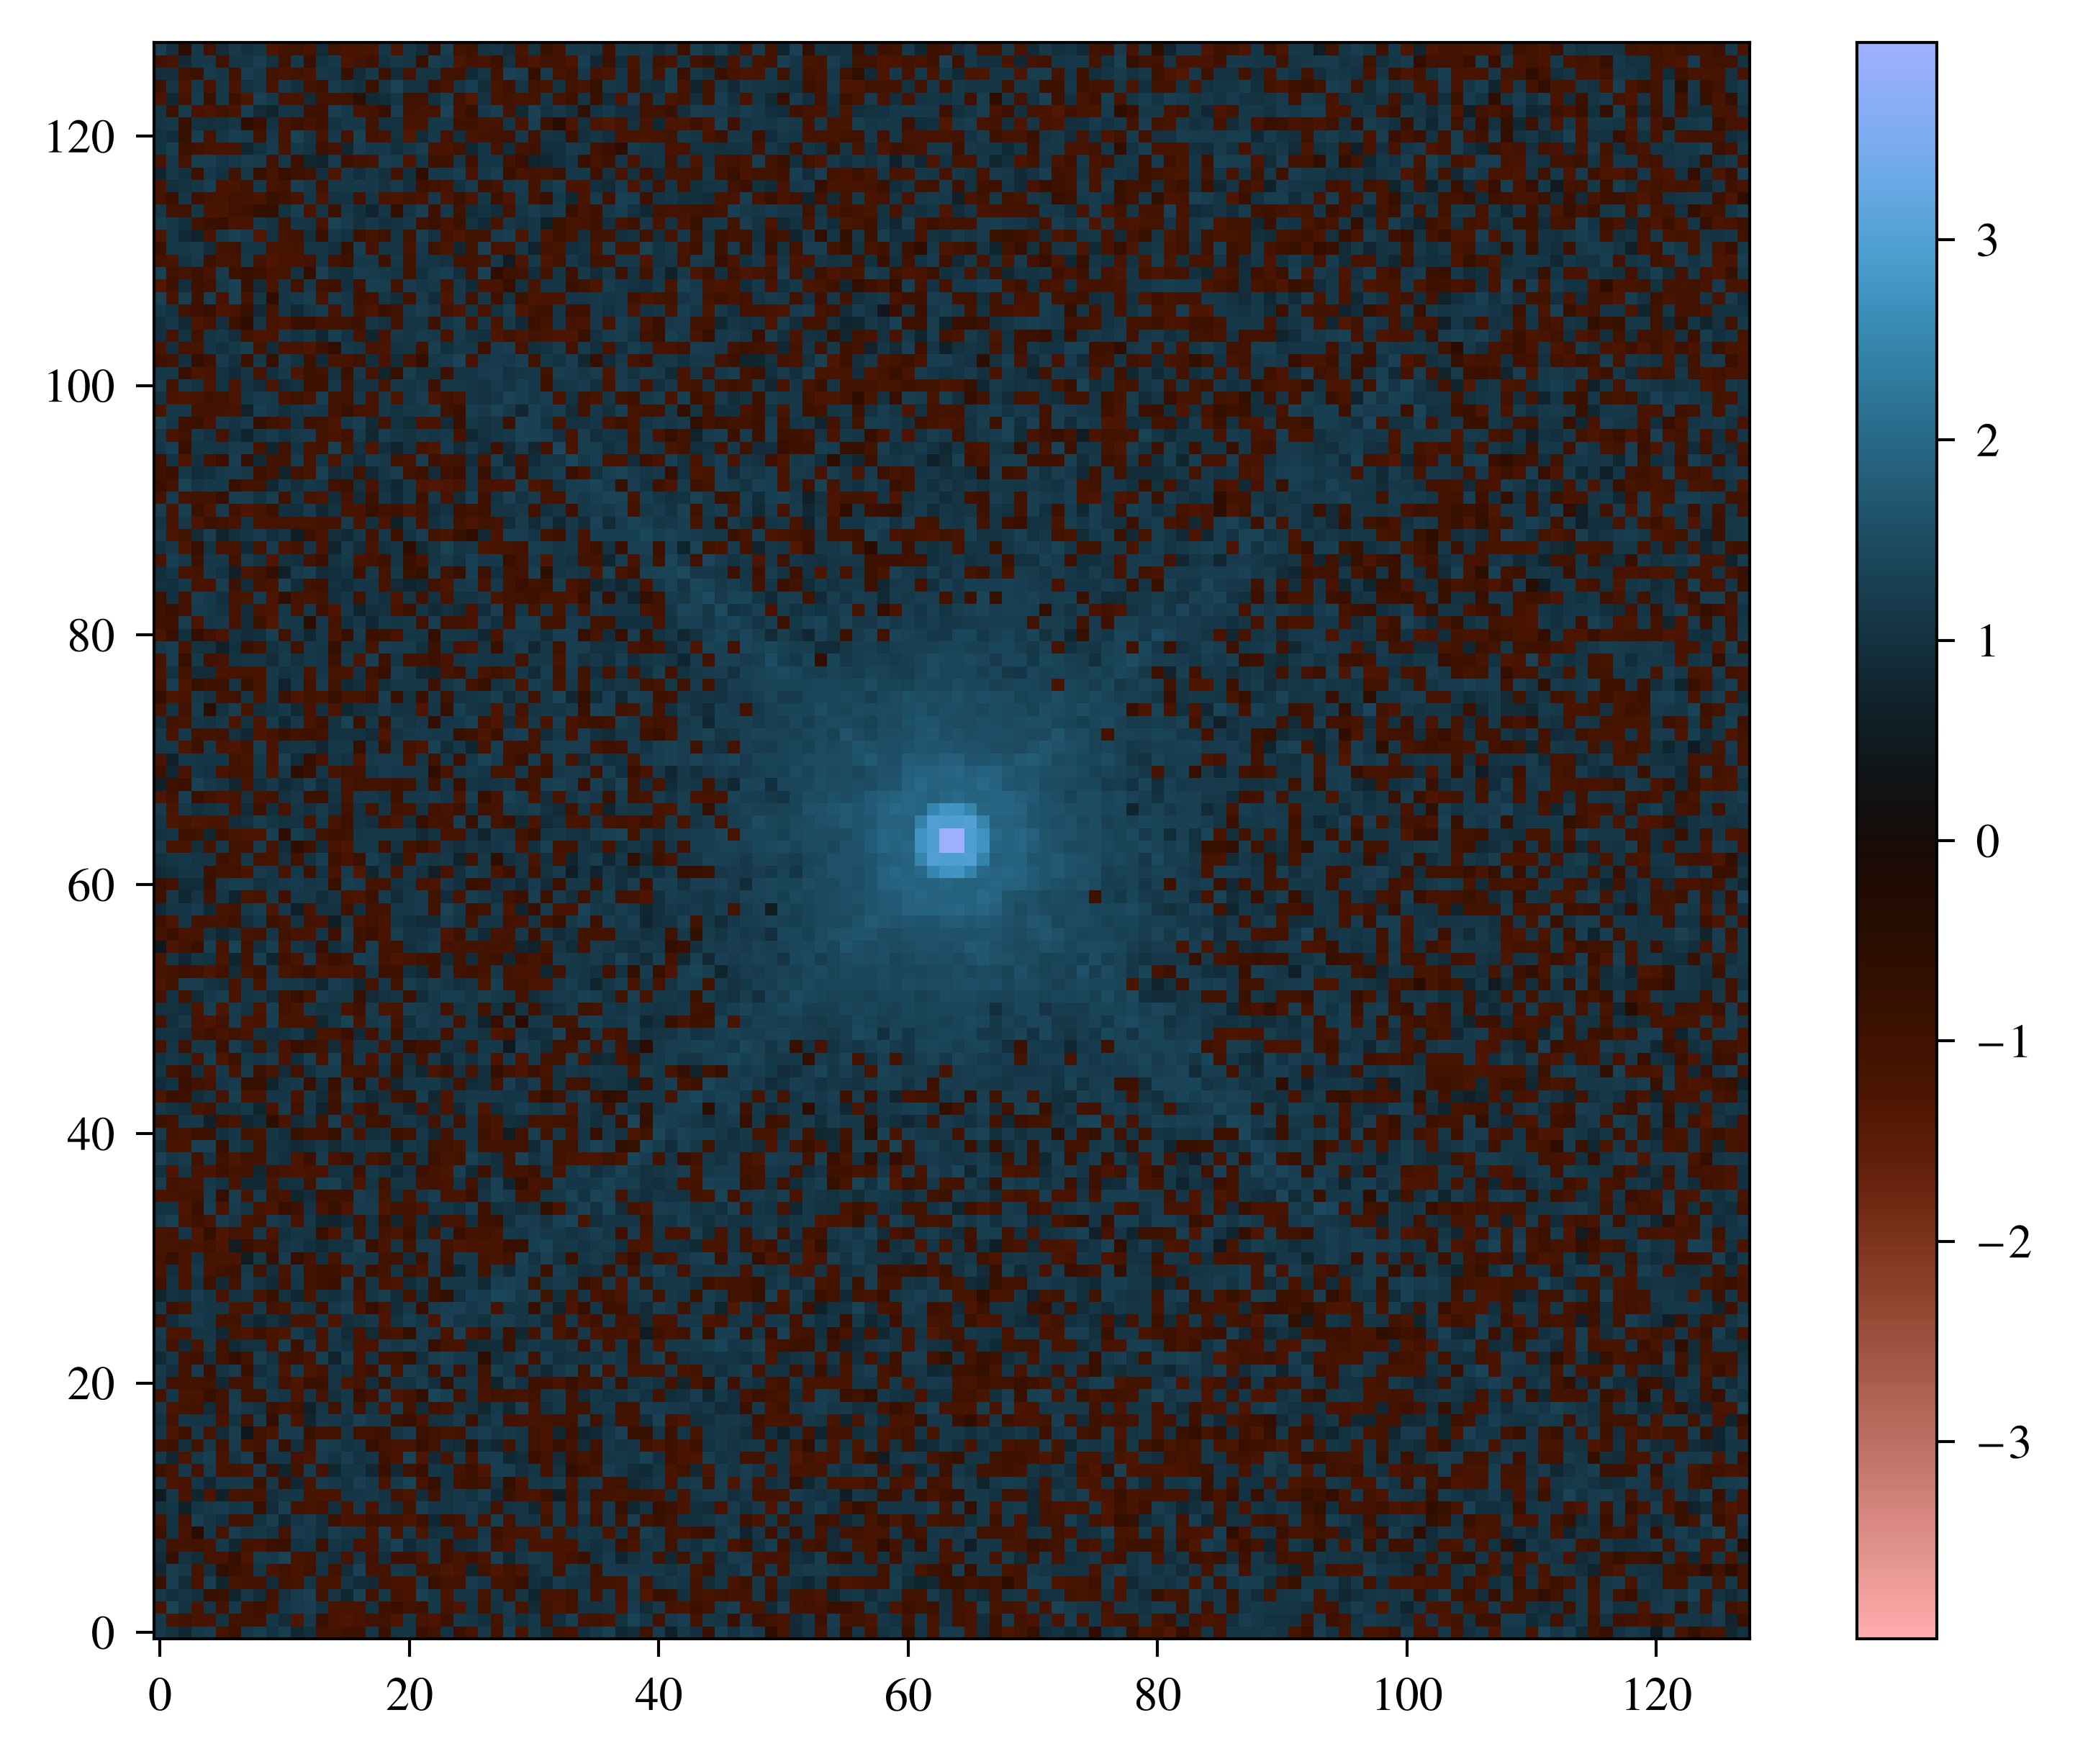

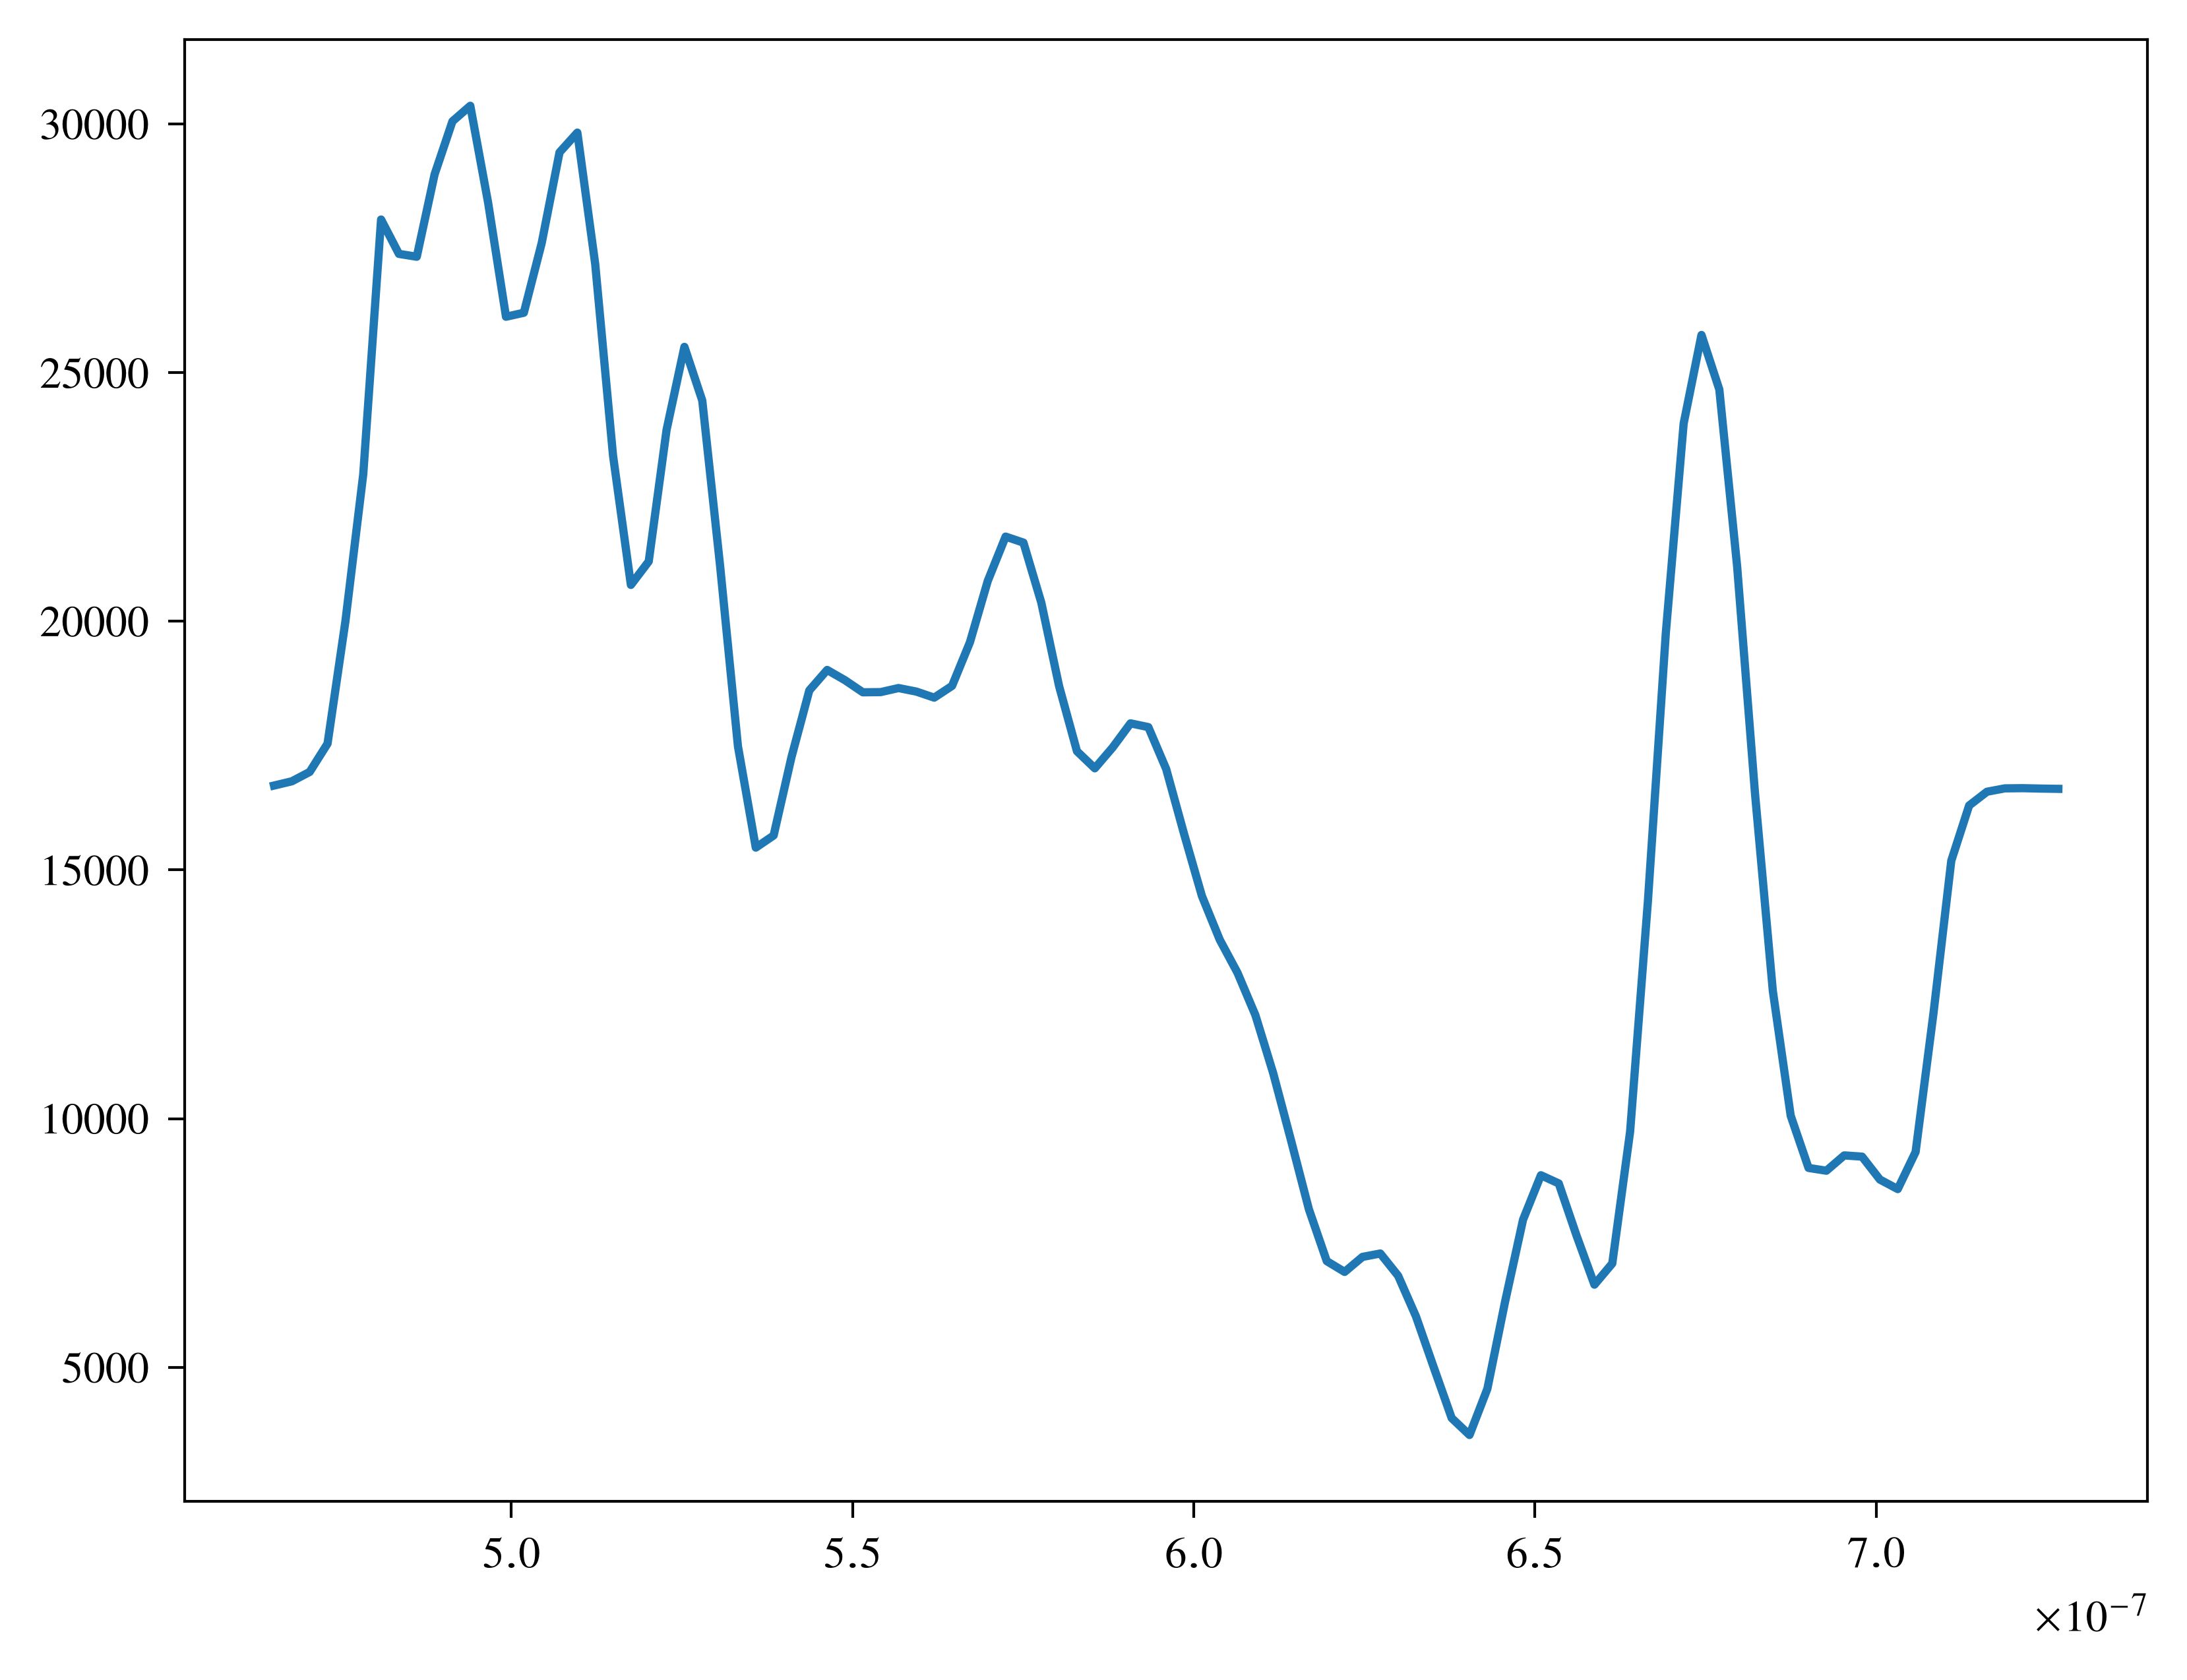

In [9]:
data_plot = np.sign(data)*np.abs(data)**(0.125)
v = np.max(np.abs(data_plot))
plt.imshow(data_plot, cmap='berlin_r', vmin=-v,vmax=v)
plt.colorbar()
plt.show()

plt.plot(waves_bin,injected_spectrum)

plt.show()
# sweet

In [10]:
# now time to recover.
from zodiax.diffops import hessian
import jax.scipy as jsp

def loss_fn(params, model, data):
    spectrum = params['spectrum']
    img = model_psf(spectrum, model)
    loss = -normal_logpdf(data, img, np.sqrt(np.maximum(data, 0) + read_noise**2)).sum()
    return loss

# do flat spectrum injection
injected_spectrum_model = (np.ones(N)/np.sum(throughput_bin)) * np.sum(data) # now do this because normalised by throughput

params = {
    "spectrum": injected_spectrum_model
}

# let us do preconditioning with the data... this is fine because we are somewhat close to maximum likelihood
# since we can just do a flat spectrum with the same total flux

# upon later consideration.. don't do wrt. data because you get strange eigval trends

# upon even later consideration... DO do wrt. data. trust.
f = lambda params: loss_fn(params, instrument, data)

H, unflatten = hessian(f, params)

H = 0.5 * (H + H.T) # symmetretise

In [11]:
# project my injected initial guess flat spectrum onto an orthogonal basis:
# Now take appropriate eigvecs and vals
eigvals, eigvecs = np.linalg.eigh(H)

idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

# Optional sign convention
for i in range(eigvecs.shape[0]):
    eigvecs = eigvecs.at[:, i].mul(np.sign(np.mean(eigvecs[5:6, i])))

a = eigvecs.T @ injected_spectrum_model

nbasis_fit = 12

spectrum_bins_fit = CombinedBasisSpectrum(waves_bin, throughput_bin, a[:nbasis_fit], eigvecs[:,:nbasis_fit])

source_fit = dl.PointSource(
    spectrum=spectrum_bins_fit
)

model_fit = dl.Telescope(optics, source_fit, detector)

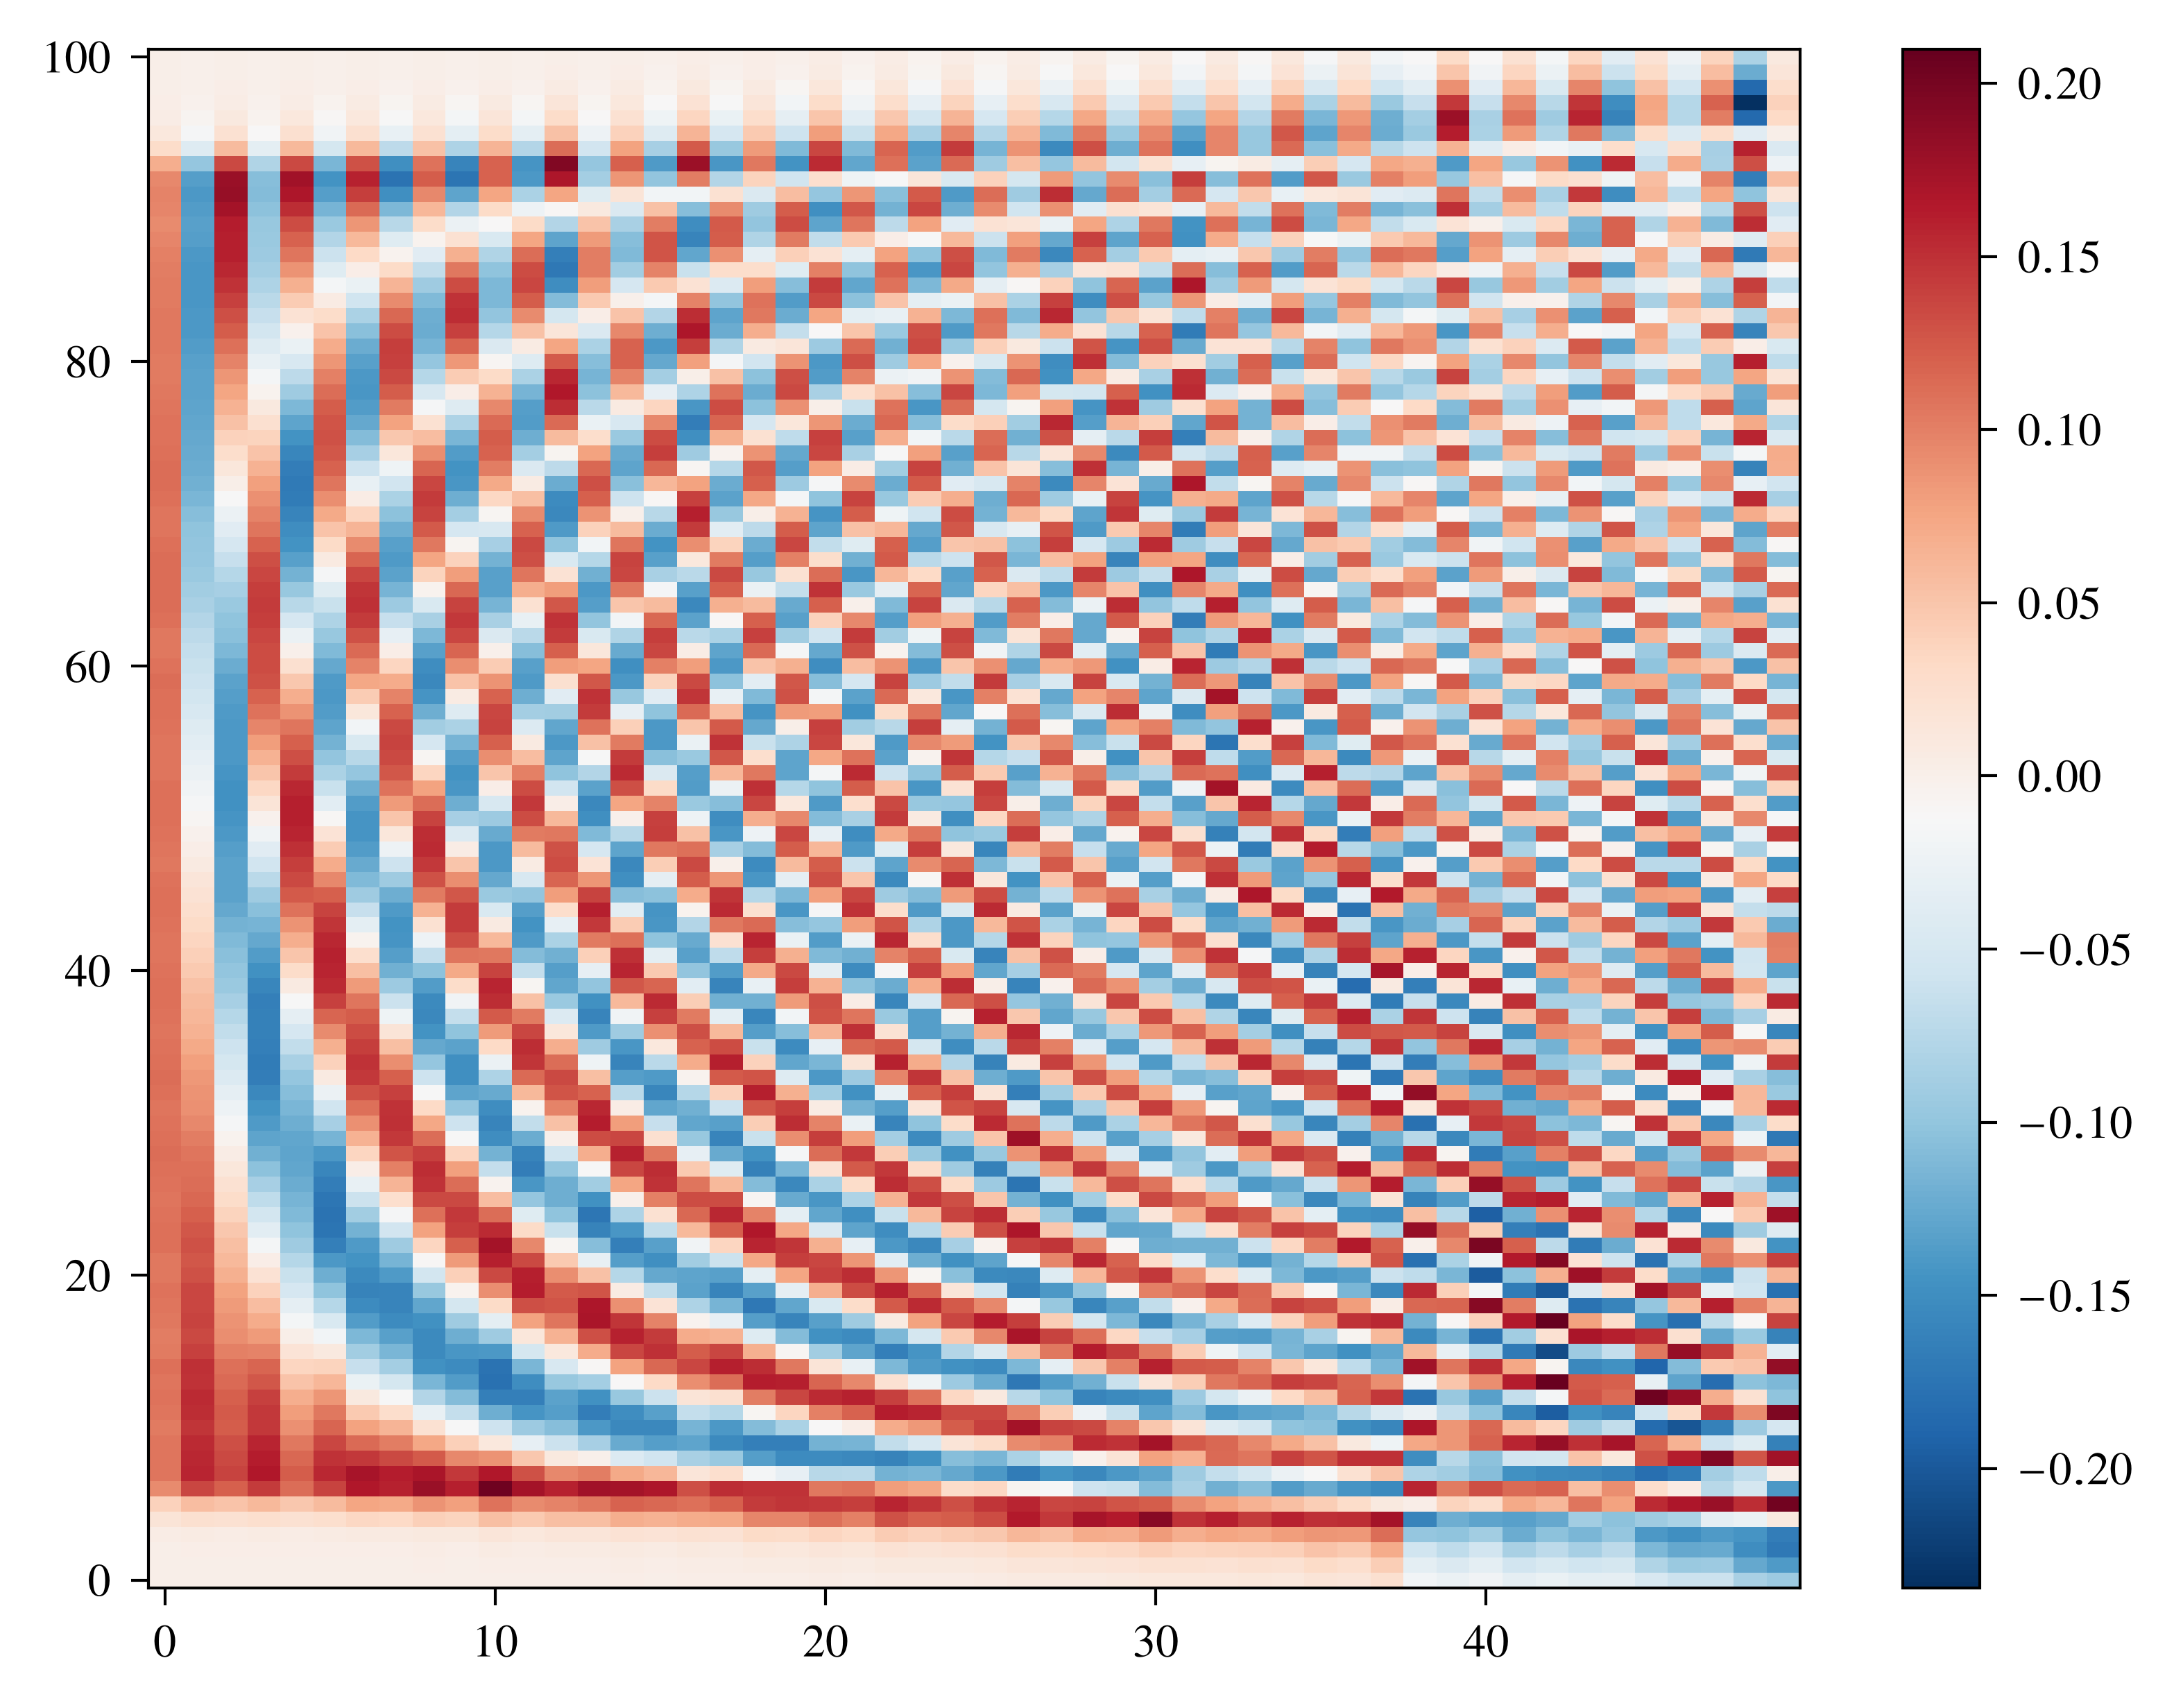

In [12]:
plt.imshow(eigvecs[:,:50], cmap='RdBu_r', aspect='auto')
plt.colorbar()
plt.show()

In [13]:
# Linear least-squares recovery of the modal coefficients.
#
# The image is linear in the per-bin spectrum s (image = A s, where column j of A
# is throughput_j * PSF_j), and the Gaussian likelihood uses data-derived variances
# W^-1 = max(d, 0) + read_noise^2. The loss is therefore exactly quadratic in s:
#     loss(s) = 0.5 (d - A s)^T W (d - A s) + const,
# so H (cell 9) = A^T W A is the observed information at *any* spectrum, and its
# eigenvectors e_k diagonalise the problem. The weighted least-squares solution in
# the leading nmodes_out modes decouples into
#     c_k = e_k^T A^T W d / lambda_k,    cov(c) = diag(1 / lambda_k),
# with no iterative optimisation. A^T W d comes from a single gradient, since
#     grad loss(s0) = H s0 - A^T W d    for any s0 > 0 (away from the eps clip).

grad_fn = jax.grad(lambda s: loss_fn({'spectrum': s}, instrument, data))

s0 = injected_spectrum_model
AtWd = H @ s0 - grad_fn(s0)

nmodes_out = 8

# the loss is quadratic, so the observed information is H everywhere
H_found = H
eigvals_found = eigvals
eigvecs_found = eigvecs

a_found = (eigvecs_found.T @ AtWd) / eigvals_found
cov_found = np.diag(1 / eigvals_found)

# eigvecs are orthonormal, so projecting the injected spectrum is just E^T s
coeffs_inject = eigvecs_found.T @ injected_spectrum

spectrum_found = eigvecs_found[:, :nmodes_out] @ a_found[:nmodes_out]
spec_var = (eigvecs_found[:, :nmodes_out]**2) @ np.diag(cov_found[:nmodes_out, :nmodes_out])


relative HVP mismatch at solution: 6.092702208372723e-10
retained-mode gradient / sigma: [ 4.18702176e-08 -1.90017932e-07 -1.28042210e-07  1.12961993e-07
  4.10824001e-07  2.72225610e-08 -7.74714003e-08  3.22461636e-07]
min recovered spectrum: 12.954493938432304
pulls (recovered - injected) / sigma: [-0.48355937  0.72392129 -0.58907092 -0.66730485  0.57542214 -0.09532975
  0.11438562  0.3572167 ]


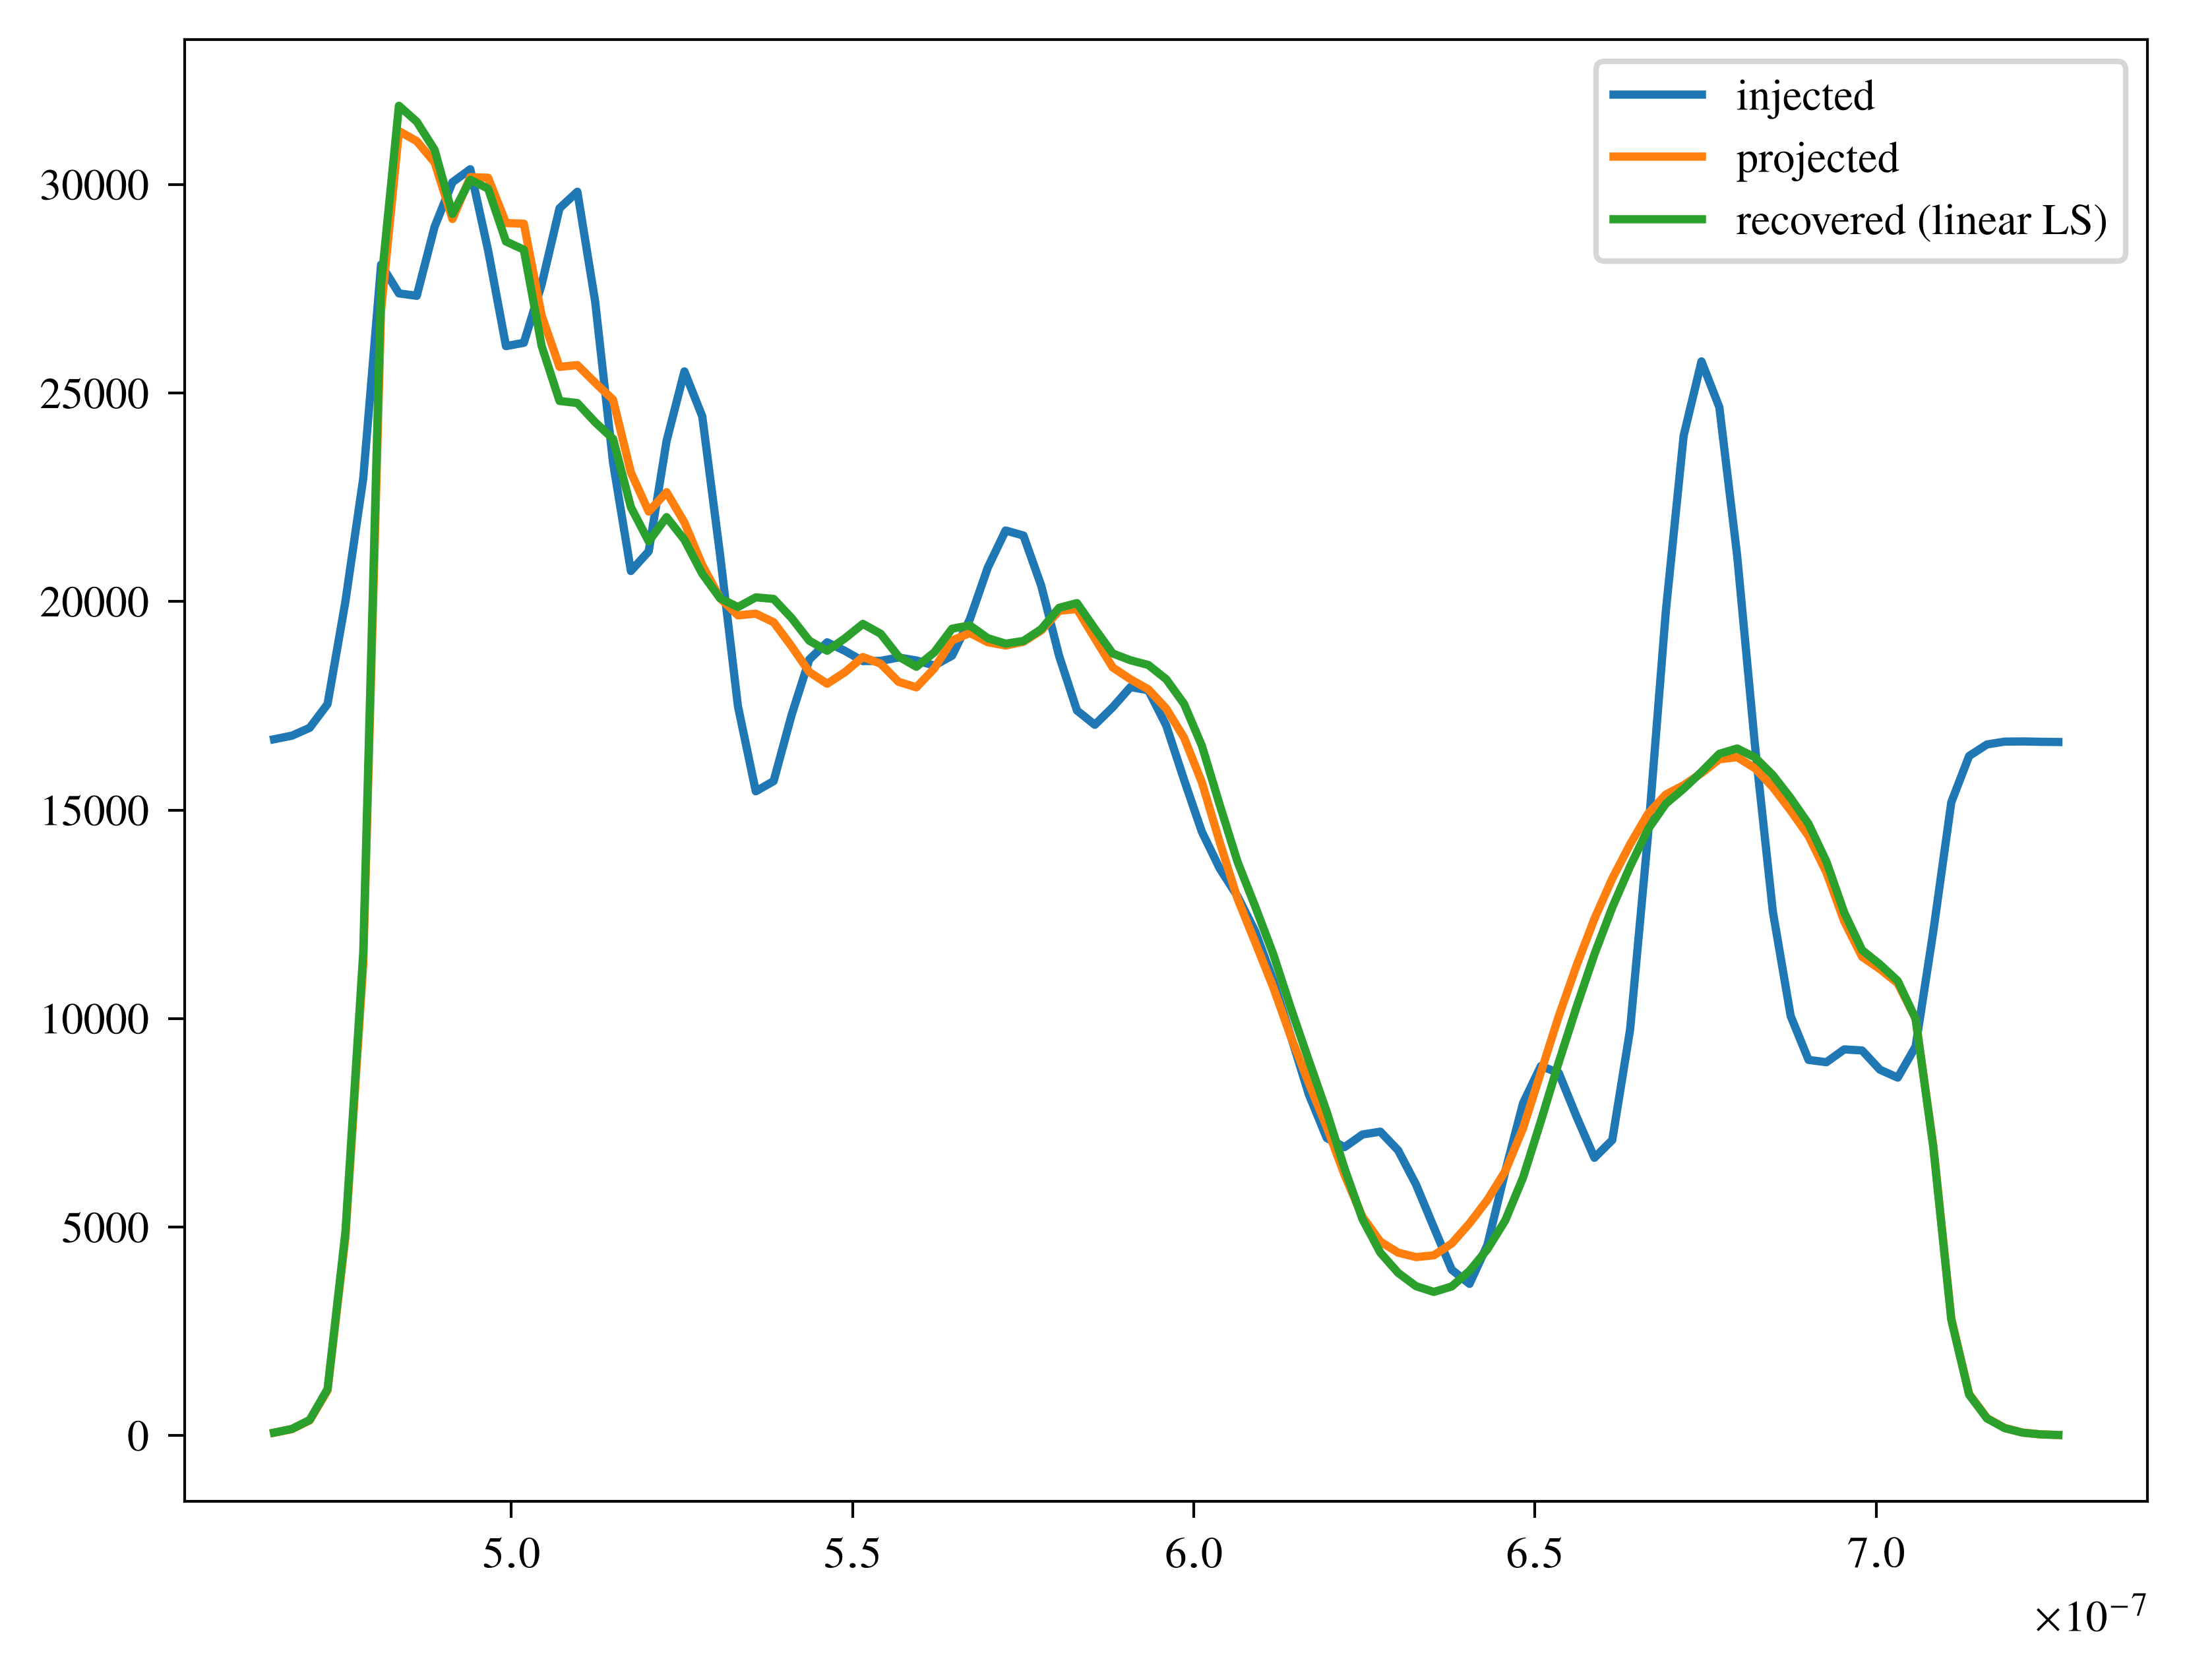

In [14]:
# Sanity checks on the linear solve
# 1) quadratic loss: the Hessian-vector product at the solution matches H @ v
v = eigvecs_found[:, 0]
hvp = jax.jvp(grad_fn, (spectrum_found,), (v,))[1]
print('relative HVP mismatch at solution:', float(np.linalg.norm(hvp - H @ v) / np.linalg.norm(H @ v)))

# 2) stationary in the retained modes (gradient in units of each mode's sigma)
g = grad_fn(spectrum_found)
print('retained-mode gradient / sigma:', eigvecs_found[:, :nmodes_out].T @ g / np.sqrt(eigvals_found[:nmodes_out]))

# 3) the model never hits the eps clip at the solution
print('min recovered spectrum:', float(np.min(spectrum_found)))

# 4) coefficient pulls against the projected injected spectrum
print('pulls (recovered - injected) / sigma:',
      (a_found[:nmodes_out] - coeffs_inject[:nmodes_out]) * np.sqrt(eigvals_found[:nmodes_out]))

plt.plot(waves_bin, injected_spectrum, label='injected')
plt.plot(waves_bin, eigvecs_found[:, :nmodes_out] @ coeffs_inject[:nmodes_out], label='projected')
plt.plot(waves_bin, spectrum_found, label='recovered (linear LS)')
plt.legend()
plt.show()


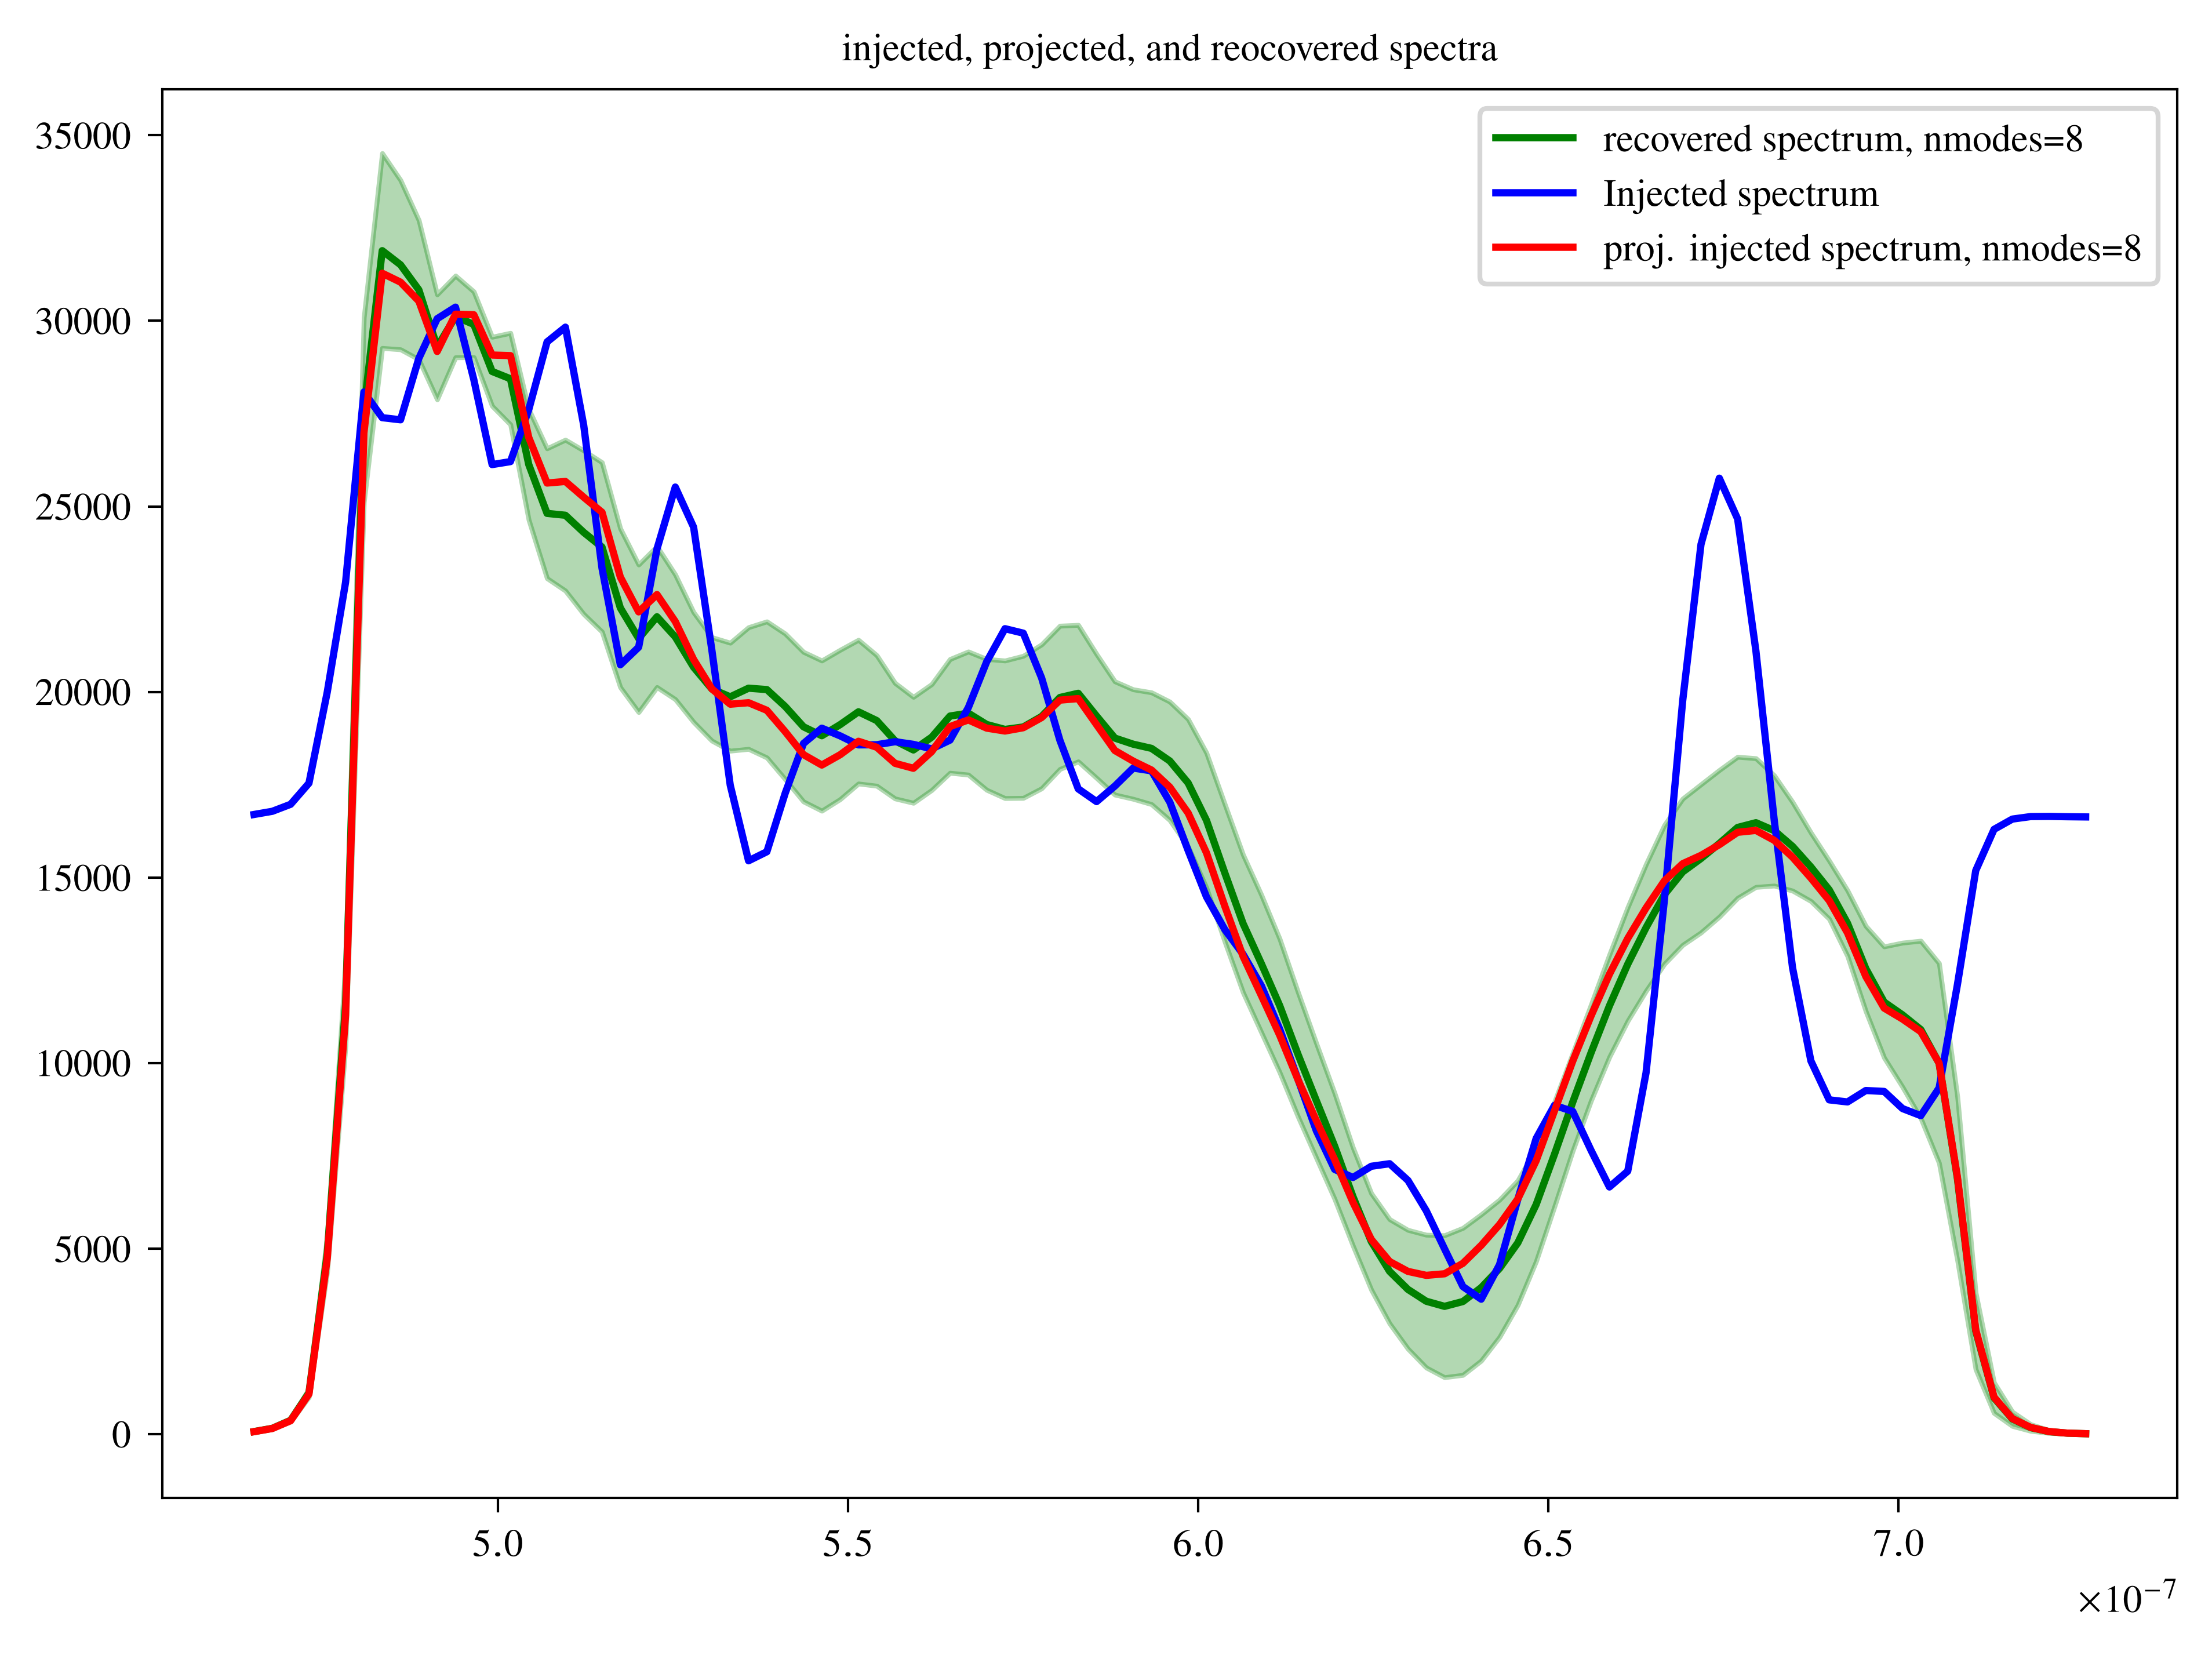

In [15]:
# plt.figure(figsize=(12,6))
plt.subplot(1,1,1)
plt.title('injected, projected, and reocovered spectra')

spec_mean = eigvecs_found[:,:nmodes_out] @ a_found[:nmodes_out]
spec_std = np.sqrt(spec_var)

plt.plot(
    waves_bin,
    spec_mean,
    color='green',
    label=f'recovered spectrum, nmodes={nmodes_out}'
)

plt.fill_between(
    waves_bin,
    spec_mean - spec_std,
    spec_mean + spec_std,
    color='green',
    alpha=0.3
)

plt.plot(waves_bin, injected_spectrum, color='blue', label='Injected spectrum')
plt.plot(waves_bin, eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out], color='red', label=f'proj. injected spectrum, nmodes={nmodes_out}')
# plt.plot(waves_bin, bandpass*np.max(injected_spectrum)/np.max(bandpass), ls='--', color='orange')
plt.legend()

# plt.subplot(1,2,2)
# plt.title('residual z-scores of projected v. recovered spectra')
# spectrum_zs = (eigvecs_new[:,:nmodes_out]@coeffs_inject[:nmodes_out] - eigvecs_new[:,:nmodes_out] @ coeffs_recov[:nmodes_out]) / ((1e0)*(np.sqrt((spec_var)))) 
# plt.hist(spectrum_zs, bins=20, density=True)
# zs = np.linspace(-5,5,1000)
# plt.plot(zs, np.exp(-zs**2/2)/np.sqrt(2*np.pi))

# plt.ylim(0,6500)
plt.tight_layout()
plt.show() 
# this looks like the strat.


In [16]:
# binning the output to the correct number of modes and propagating uncertainties....
# retained info ~ actual info
fisher_cdf = np.cumsum(np.diag(H_found))/np.sum(np.diag(H_found))

wave = np.asarray(waves_bin)
n_bins = nmodes_out

# Native cell edges from wavelength centres
native_edges = np.empty(len(wave) + 1)
native_edges = native_edges.at[1:-1].set(
    0.5 * (wave[:-1] + wave[1:])
)
native_edges = native_edges.at[0].set(
    wave[0] - 0.5 * (wave[1] - wave[0])
)
native_edges = native_edges.at[-1].set(
    wave[-1] + 0.5 * (wave[-1] - wave[-2])
)

In [17]:
import jax
import jax.numpy as np
import numpy as onp
from scipy.optimize import minimize

# Retained modal projector
Q_N = eigvecs_found[:, :nmodes_out]
P = Q_N @ Q_N.T

wave = np.asarray(waves_bin)
native_widths = np.diff(native_edges)

wave_min = wave[0]
wave_max = wave[-1]
full_span = wave_max - wave_min

# Maximum permitted inward displacement of either outer edge
max_edge_shift = 0.1 * full_span

In [18]:
def construct_B_from_edges(wave_lo, wave_hi):
    """Construct equal-width top-hat bins between two wavelength cutoffs."""

    target_edges = np.linspace(
        wave_lo,
        wave_hi,
        n_bins + 1,
    )

    target_centres = 0.5 * (
        target_edges[:-1] + target_edges[1:]
    )

    target_widths = np.diff(target_edges)

    # Shape: (n_bins, n_native_wavelengths)
    overlap_left = np.maximum(
        target_edges[:-1, None],
        native_edges[:-1][None, :],
    )

    overlap_right = np.minimum(
        target_edges[1:, None],
        native_edges[1:][None, :],
    )

    overlap = np.maximum(
        0.0,
        overlap_right - overlap_left,
    )

    # Code convention: rows are bins
    B = overlap / native_widths[None, :]

    return B, target_edges, target_centres, target_widths

In [19]:
@jax.jit
def edge_objective(edges):
    wave_lo, wave_hi = edges

    B, _, _, _ = construct_B_from_edges(
        wave_lo,
        wave_hi,
    )

    projected_B = B @ P

    return (
        np.sum((projected_B - B)**2)
        / np.sum(B**2)
    )

In [20]:
objective_jit = jax.jit(edge_objective)

initial_edges = onp.array([
    float(wave_min),
    float(wave_max),
])

bounds = [
    (
        float(wave_min),
        float(wave_min + max_edge_shift),
    ),
    (
        float(wave_max - max_edge_shift),
        float(wave_max),
    ),
]

result = minimize(
    lambda x: float(
        objective_jit(np.asarray(x))
    ),
    x0=initial_edges,
    method="Powell",
    bounds=bounds,
    options={
        "xtol": 1e-12,
        "ftol": 1e-12,
        "maxiter": 1000,
    },
)

wave_lo_opt, wave_hi_opt = result.x

B, target_edges, target_centres, target_widths = (
    construct_B_from_edges(
        np.asarray(wave_lo_opt),
        np.asarray(wave_hi_opt),
    )
)

K = B @ P

print(
    f"Lower cutoff: {wave_lo_opt * 1e10:.3f} Angstrom"
)
print(
    f"Upper cutoff: {wave_hi_opt * 1e10:.3f} Angstrom"
)
print(
    f"Retained wavelength span: "
    f"{(wave_hi_opt - wave_lo_opt) / float(full_span):.4%}"
)
print(
    f"Relative squared projection error: "
    f"{result.fun:.6e}"
)

Lower cutoff: 4749.647 Angstrom
Upper cutoff: 7117.406 Angstrom
Retained wavelength span: 90.5504%
Relative squared projection error: 1.637565e-01


In [21]:
# Range of actual lower and upper wavelength edges explored
n_grid = 150

wave_lo_grid = np.linspace(
    wave_min,
    wave_min + max_edge_shift,
    n_grid,
)

wave_hi_grid = np.linspace(
    wave_max - max_edge_shift,
    wave_max,
    n_grid,
)

# Evaluate edge_objective([wave_lo, wave_hi]) over the 2D grid
def objective_for_lower_edge(wave_lo):
    return jax.vmap(
        lambda wave_hi: edge_objective(
            np.array([wave_lo, wave_hi])
        )
    )(wave_hi_grid)

loss_grid = jax.vmap(
    objective_for_lower_edge
)(wave_lo_grid)

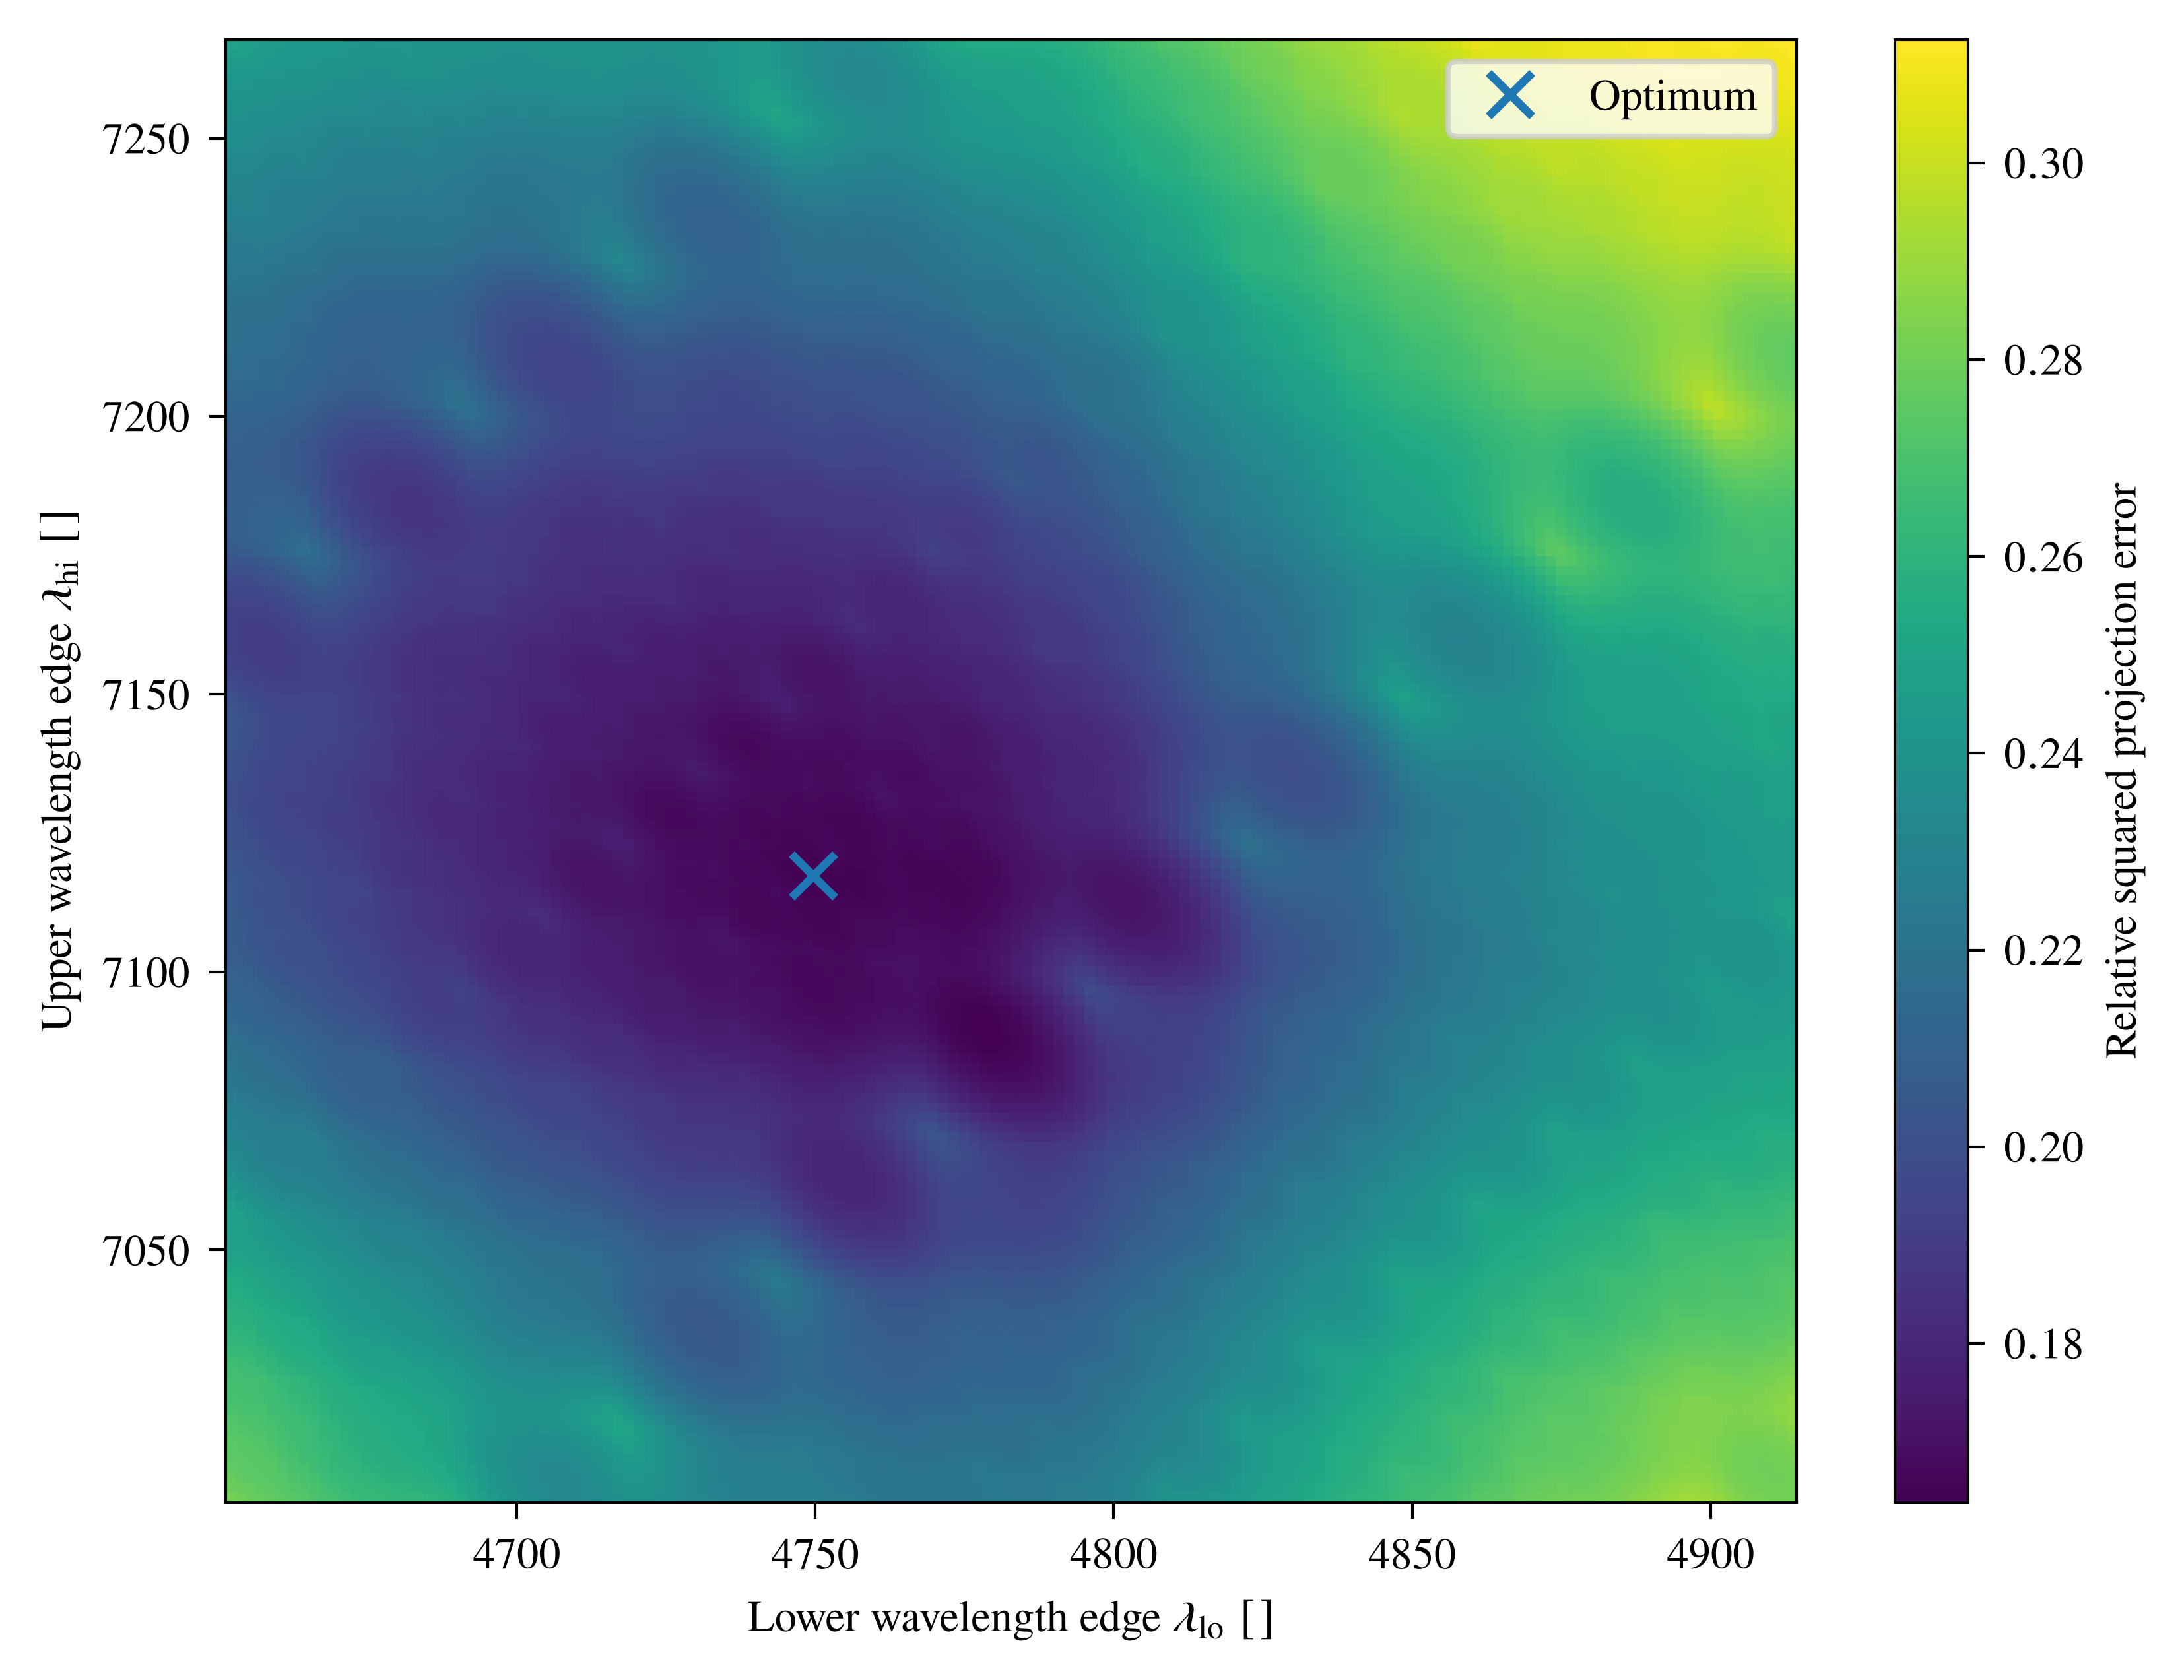

In [22]:
fig, ax = plt.subplots()

mesh = ax.pcolormesh(
    np.asarray(wave_lo_grid) * 1e10,
    np.asarray(wave_hi_grid) * 1e10,
    np.asarray(loss_grid).T,
    shading="auto",
)

ax.plot(
    wave_lo_opt * 1e10,
    wave_hi_opt * 1e10,
    "x",
    markersize=8,
    markeredgewidth=1.5,
    label="Optimum",
)

ax.set_xlabel(
    r"Lower wavelength edge $\lambda_{\rm lo}\ [\mathrm{\AA}]$"
)
ax.set_ylabel(
    r"Upper wavelength edge $\lambda_{\rm hi}\ [\mathrm{\AA}]$"
)

fig.colorbar(
    mesh,
    ax=ax,
    label="Relative squared projection error",
)

ax.legend()
plt.show()

In [23]:
# get far edges
# tail = 0.005 # 0.5% on each tail.
# tail = 0.000257
# # tail = 0.0018
# wave_lo = np.interp(tail, fisher_cdf, waves_bin)
# wave_hi = np.interp(1 - tail, fisher_cdf, waves_bin)
wave_lo = wave_lo_opt
wave_hi = wave_hi_opt

# construct edges, centres, widths
target_edges = np.linspace(wave_lo, wave_hi, n_bins + 1)
target_centres = 0.5 * (target_edges[:-1] + target_edges[1:])
target_widths = np.diff(target_edges)

# overlap matrix
B = np.zeros((n_bins, len(wave)))

for b in range(n_bins):
    for j in range(len(wave)):
        overlap = np.maximum(
            0.0,
            np.minimum(target_edges[b + 1], native_edges[j + 1])
            - np.maximum(target_edges[b], native_edges[j]),
        )

        B = B.at[b, j].set(overlap)

native_widths = np.diff(native_edges)

B = B / native_widths[None, :]

bin_flux = B @ spec_mean
# just define that
E = eigvecs_found[:, :nmodes_out] # uncomment if not doing the above thing

BE = B @ E

coarse_cov = BE @ cov_found[:nmodes_out, :nmodes_out] @ BE.T
coarse_sigma = np.sqrt(np.diag(coarse_cov))

bin_recov_flux_angstrom = bin_flux/target_widths * 1e-10
recov_flux_angstrom = spec_mean/native_widths * 1e-10
injec_flux_angstrom = injected_spectrum/native_widths * 1e-10

waves_angstrom = waves_bin * 1e10
bin_centres_angstrom = target_centres * 1e10
bin_widths_angstrom = target_widths * 1e10

coarse_sigma_angstrom = coarse_sigma/target_widths * 1e-10
recov_std_angstrom = spec_std/native_widths * 1e-10

projec_flux_angstrom = eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out]/native_widths * 1e-10

injected_bin_flux_angstrom = B @ injected_spectrum/target_widths * 1e-10

projected_bin_flux_angstrom = B @ eigvecs_found[:,:nmodes_out] @ coeffs_inject[:nmodes_out]/target_widths * 1e-10

# K = B @ E @ E.T # again uncomment if not doing the above cell

In [24]:
coarse_cov_angstrom = (
    coarse_cov
    / target_widths[:, None]
    / target_widths[None, :]
    * 1e-20
)

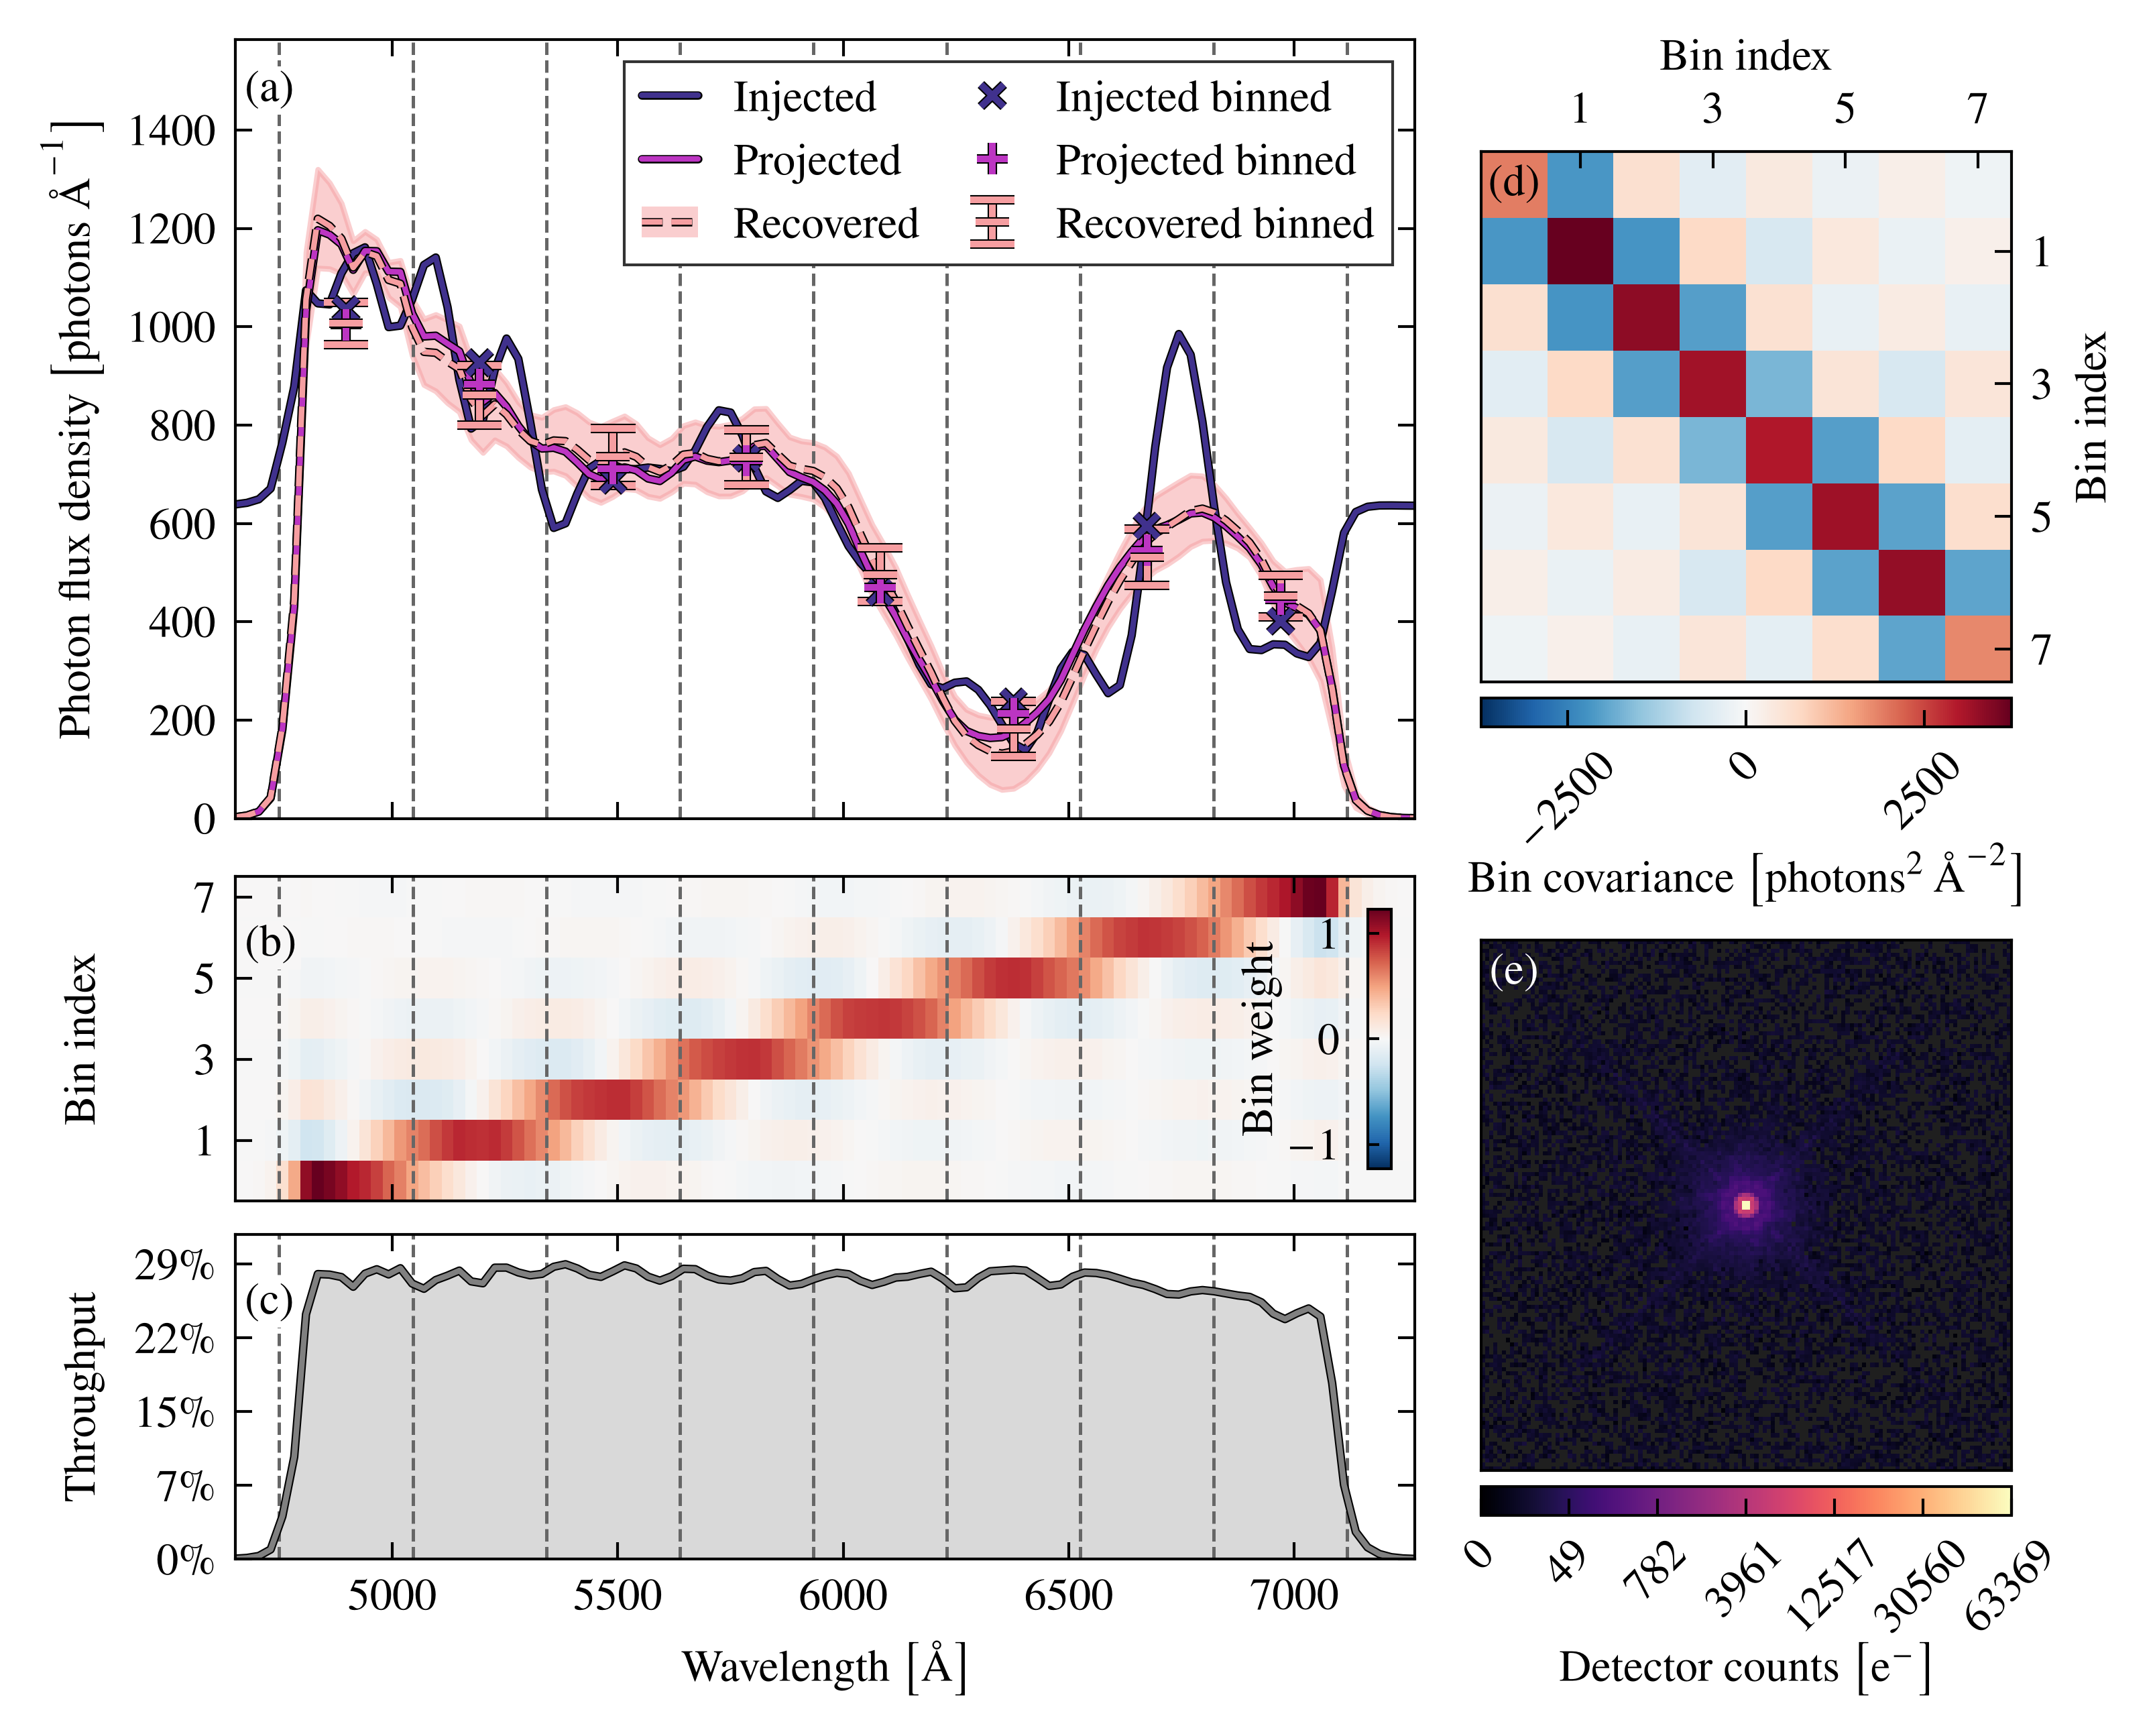

In [28]:
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from cmap import Colormap

cmap = Colormap('bubblegum').to_mpl()

c_inj = cmap(0.2)
c_proj = cmap(0.55)
c_recov = cmap(0.9)

path_effects = [
    pe.Stroke(linewidth=2.5, foreground="k"),
    pe.Normal(),
]

path_effects_thin = [
    pe.Stroke(linewidth=1.5, foreground="k"),
    pe.Normal(),
]

path_effects_thin2 = [
    pe.Stroke(linewidth=1.7, foreground="k"),
    pe.Normal(),
]

label_bbox = dict(boxstyle="square,pad=0.1", facecolor="white", edgecolor="none")

# Full double-column width; left 2/3 is the spectrum figure, right 1/3 is
# a column holding the bin covariance (top) and detector image (bottom).
fig = plt.figure(
    figsize=(fig_width, 0.8 * fig_width),
    layout="constrained",
)
subfig_spec, subfig_col = fig.subfigures(
    1, 2,
    width_ratios=[2, 1],
    wspace=0.0,
)

ax, ax_K, ax_info = subfig_spec.subplots(
    3, 1,
    sharex=True,
    gridspec_kw={"height_ratios": [2.4, 1, 1]},
)
ax_cov, ax_img = subfig_col.subplots(2, 1)
# the square images can't fill the column height; pin them to the top and bottom
# so (e)'s colourbar label lines up with the wavelength label
ax_cov.set_anchor("N")
ax_img.set_anchor("S")

#### a: injected / projected / recovered spectra
for edge in target_edges:
    ax.axvline(
        edge*1e10,
        color="0.4",
        linewidth=0.6,
        linestyle="--",
    )

# leave headroom above the tallest curve / error bar for the legend
y_top = 1.2 * max(
    float(np.max(injec_flux_angstrom)),
    float(np.max(recov_flux_angstrom + recov_std_angstrom)),
    float(np.max(bin_recov_flux_angstrom + coarse_sigma_angstrom)),
)
ax.set_ylim(0, y_top)

ax.plot(waves_angstrom, injec_flux_angstrom, color=c_inj, label=r'Injected',
        path_effects=path_effects_thin,
        solid_capstyle='round',
        ls='-',
        linewidth=1.0,
        )

ax.plot(waves_angstrom, projec_flux_angstrom, color=c_proj, label=r'Projected',
        path_effects=path_effects_thin,
        ls='-',
        solid_capstyle='round',
        linewidth=1.0,
        )

recov_line = ax.plot(
    waves_angstrom,
    recov_flux_angstrom,
    color=c_recov,
    path_effects=path_effects_thin,
    solid_capstyle='round',
    ls='--',
    linewidth=1.0,
)

recov_fill = ax.fill_between(
    waves_angstrom,
    recov_flux_angstrom - recov_std_angstrom,
    recov_flux_angstrom + recov_std_angstrom,
    color=c_recov,
    alpha=0.5,
)

ax.errorbar(bin_centres_angstrom, bin_recov_flux_angstrom, yerr=coarse_sigma_angstrom, fmt="_", ecolor=c_recov,
            capsize=5*0.8,
            elinewidth=1.5*0.8,
            capthick=1.5*0.8,
            path_effects=path_effects_thin2,
            label='Recovered binned',
            markerfacecolor='none',
            markeredgecolor=c_recov,
            markeredgewidth=1.5*0.8,)

ax.plot(
    bin_centres_angstrom,
    injected_bin_flux_angstrom,
    "x",
    color=c_inj,
    markersize=5*0.8,
    markeredgewidth=1.5*0.8,
    label=r"Injected binned",
    path_effects=path_effects_thin2,
)

ax.plot(
    bin_centres_angstrom,
    projected_bin_flux_angstrom,
    "+",
    color=c_proj,
    markersize=7*0.8,
    markeredgewidth=1.5*0.8,
    label=r"Projected binned",
    path_effects=path_effects_thin2,
)

ax.set_ylabel(r'Photon flux density $\big[\mathrm{photons}\  \text{\AA}^{-1}\big]$')

handles, labels = ax.get_legend_handles_labels()

recov_legend = (
    Patch(
        facecolor=c_recov,
        edgecolor="none",
        alpha=0.5,
    ),
    Line2D(
        [0], [0],
        color=c_recov,
        linewidth=1.0,
        path_effects=path_effects_thin,
        solid_capstyle="round",
        ls='--'
    ),
)
handles.insert(2, recov_legend)
labels.insert(2, "Recovered")

leg = ax.legend(handles, labels,
          ncols=2,
          columnspacing=1.0,
          handlelength=1.25,
          loc='upper right',
          frameon=True,
          framealpha=1,
          edgecolor='0.2',
          fancybox=False)
leg.get_frame().set_linewidth(0.5)

ax.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
)

ax.text(
    0.008, 0.96,
    r'(a)',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='k',
    bbox=label_bbox,
)

#### b: effective bin kernels
v = np.max(np.abs(K))
im = ax_K.imshow(
    K,
    origin="lower",
    aspect="auto",
    interpolation="auto",
    extent=[
        native_edges[0] * 1e10,
        native_edges[-1] * 1e10,
        0.5,
        K.shape[0] + 0.5,
    ],
    cmap="RdBu_r",
    vmin=-v,
    vmax=v,
)

ax_K.set_ylabel(r"Bin index")
ax_K.set_yticks(
    np.arange(2, K.shape[0] + 1, 2),
    labels=[f"{i}" for i in range(1, K.shape[0], 2)],
)
ax_K.tick_params(
    axis="y",
    direction="in",
    left=True,
    right=False,
    labelleft=True,
)
ax_K.text(
    0.008, 0.85,
    r'(b)',
    transform=ax_K.transAxes,
    ha='left',
    va='top',
    color='k',
    bbox={**label_bbox, "facecolor": plt.get_cmap("RdBu_r")(0.5)},
)

ax_K.tick_params(
    axis="x",
    direction="in",
    top=True,
    bottom=True
)

cax = ax_K.inset_axes([0.96, 0.1, 0.02, 0.8])

cbar_K = fig.colorbar(im, cax=cax, orientation="vertical")
cbar_K.set_ticks([-1, 0, 1], labels=[r"$-1$", r"$0$", r"$1$"])
cbar_K.ax.tick_params(
    top=False,
    direction='in',
    bottom=False,
    labelbottom=False,
    labeltop=False,
    left=True,
    right=False,
    labelleft=True,
    labelright=False,
    )

cbar_K.ax.yaxis.set_label_position('left')
cbar_K.set_label(r"Bin weight", labelpad=1)
cbar_K.ax.tick_params(pad=5.0, length=2.0)   # smaller = labels closer to the bar

for edge in target_edges:
    ax_K.axvline(
        edge * 1e10,
        color="0.4",
        linewidth=0.6,
        linestyle="--",
    )

#### c: throughput
for edge in target_edges:
    ax_info.axvline(
        edge*1e10,
        color="0.4",
        linewidth=0.6,
        linestyle="--",
    )

ax_info.plot(waves_angstrom,
             throughput_bin/np.max(throughput_bin),
             color='grey',
             path_effects=path_effects_thin,
             linewidth=1.0,
             ls='-'
             )

ax_info.fill_between(
    waves_angstrom,
    0,
    throughput_bin/np.max(throughput_bin),
    color="0.85",
)
ax_info.set_ylim(0, 1.1)

ax_info.set_xlabel(r"Wavelength $\big[\text{\AA}\big]$")
ax_info.set_ylabel(r"Throughput")
ax_info.set_xlim(np.min(waves_angstrom), np.max(waves_angstrom))

# curve is normalised to its peak; label 0, half and full peak in percent
peak_throughput = float(np.max(throughput_bin))
ax_info.set_yticks(
    [0, 0.25, 0.5, 0.75, 1],
    labels=[rf"{100 * frac * peak_throughput:.0f}\%" for frac in (0, 0.25, 0.5, 0.75, 1)],
)

ax_info.tick_params(
    axis="both",
    which="both",
    direction="in",
    top=True,
    right=True,
    labelleft=True,
)

ax_info.text(
    0.008, 0.85,
    r'(c)',
    transform=ax_info.transAxes,
    ha='left',
    va='top',
    color='k',
    bbox=label_bbox,
)

subfig_spec.align_ylabels([ax, ax_K, ax_info])

#### d: bin covariance
v = np.max(np.abs(coarse_cov_angstrom))

# axes position of the centre of the top-left covariance cell
corner_cell = (
    0.5 / coarse_cov_angstrom.shape[1],
    1 - 0.5 / coarse_cov_angstrom.shape[0],
)

im_cov = ax_cov.imshow(
    coarse_cov_angstrom,
    vmin=-v,
    vmax=v,
    cmap='RdBu_r',
    origin='upper'
)

ax_cov.tick_params(direction='in')

# x axis on top, y axis on right
ax_cov.xaxis.tick_top()
ax_cov.xaxis.set_label_position('top')
ax_cov.set_xlabel('Bin index')
ax_cov.set_ylabel('Bin index')
ax_cov.yaxis.tick_right()
ax_cov.yaxis.set_label_position('right')
ax_cov.set_xticks([1, 3, 5, 7])
ax_cov.set_yticks([1, 3, 5, 7])

# colourbars sit just below each image and match its width exactly
cbar_box = [0, -0.085, 1, 0.055]

cbar_cov = fig.colorbar(
    im_cov,
    cax=ax_cov.inset_axes(cbar_box),
    orientation='horizontal',
)

cbar_cov.ax.tick_params(direction='in', labelrotation=45)
cbar_cov.set_label(
    r'Bin covariance $\big[ \mathrm{photons}^2\,\text{\AA}^{-2} \big]$',
    labelpad=-3
)

ax_cov.text(
    *corner_cell,
    r'(d)',
    transform=ax_cov.transAxes,
    ha='center',
    va='center',
    color='k'
)

#### e: detector image
gamma = 0.25

data_nonnegative = np.where(data < 0, np.nan, data)
data_flattened = data_nonnegative**gamma
v = float(np.nanmax(data_flattened))

cmap_img = plt.get_cmap("magma").copy()
cmap_img.set_bad("0.125")

im_img = ax_img.imshow(
    data_flattened,
    vmin=0,
    vmax=v,
    cmap=cmap_img,
    origin="lower",
)
ax_img.set_yticks([])
ax_img.set_xticks([])

cbar_img = fig.colorbar(
    im_img,
    cax=ax_img.inset_axes(cbar_box),
    orientation="horizontal",
)

# Evenly spaced in displayed colour, labelled in original counts.
tick_positions = np.linspace(0, v, 7)
cbar_img.set_ticks(tick_positions)
cbar_img.set_ticklabels([
    f"{tick**(1 / gamma):.0f}" for tick in tick_positions
])

cbar_img.ax.tick_params(direction='in', labelrotation=45)
cbar_img.set_label(r'Detector counts $\big[ \mathrm{e}^{-} \big]$',
                   labelpad=0.0)

ax_img.text(
    *corner_cell,
    r'(e)',
    transform=ax_img.transAxes,
    ha='center',
    va='center',
    color='white'
)

plt.savefig('injec_recov_jatis.pdf', dpi=600, backend='pgf')
plt.show()